# 07 — Chạy lại hợp nhất: sửa lỗi phương pháp của notebook 06

Notebook này **không phải** một thử nghiệm mới. Nó chạy lại các phép đo của notebook 03–06 theo
một giao thức chặt hơn, sau khi bản rà soát `reports/Bao_cao_ra_soat_notebook06.md` tìm ra
9 lỗi phương pháp trong notebook 06.

## Quy ước trình bày

- **Ô code chỉ tính và hiện bảng.** Không có đoạn văn giải thích nào nằm trong code.
- **Mọi diễn giải nằm ở ô Text riêng**, ngay sau ô code tương ứng, tiêu đề *"Đọc kết quả"*.
- Ô code chỉ in hai loại thông tin: **tiến trình** (thời gian fit) và **kiểm chứng** (assert đã qua).
- Số trong các ô Text là số của lần chạy **08/10/2026** (300 cây, seed 42). Số sống luôn nằm ở
  bảng do ô code hiện ra ngay phía trên.

## Kỷ luật được khai báo TRƯỚC khi chạy

| # | Quy tắc | Lỗi của NB06 mà nó sửa |
|---|---|---|
| 1 | **Quy tắc chọn khai báo trước:** tối đa Recall với `FPR ≤ 0,10`, đo **trên `test-dev`**. `test-final` chỉ chạm một lần ở bước báo cáo | NB06 chọn bằng `idxmax(accuracy)` trên chính `test-final` → winner's curse |
| 2 | Mọi bảng so sánh đều kèm **chỉ số bền với tỷ lệ lớp**: Balanced Accuracy, MCC, ROC-AUC | NB06 so Accuracy giữa các ô có π_test từ 0,3332 đến 0,6406 |
| 3 | Mỗi phép so sánh in rõ `n` và `π_test` của tập đánh giá | NB06 tuyên bố "chỉ ba yếu tố thay đổi" nhưng cả ba đều làm đổi tập đánh giá |
| 4 | Câu hỏi khử trùng lặp đo bằng cách **giữ nguyên tập đánh giá** | NB06 đổi cả tập đánh giá → ra +0,0294, ngược dấu với phép đo sạch đã có |
| 5 | Phân rã mức cải thiện phải dùng **cùng một đơn vị** | NB06 chia ΔAccuracy cho ΔPR-AUC để ra "85%/15%" |
| 6 | KS tính trên dữ liệu **đã làm sạch**, chỉ feature **model thật dùng** | NB06 tính trên dữ liệu thô, kể cả 11 cột đã bỏ |
| 7 | Báo cáo biên độ thuật toán **cả hai cách** (có và không có Logistic Regression) | NB06 in 0,2142 nhưng kết luận bằng 0,0138, không nói đã loại LR |
| 8 | **Recall theo loại tấn công cho MỌI cấu hình** | NB06 chỉ báo cáo cho cấu hình thắng → che mất Fuzzers tụt từ 0,82 xuống 0,43 |
| 9 | Kiểm tra **độ bền theo seed** | NB06 bỏ bước này (NB05 có) |

Thêm: mỗi model **fit một lần**, mọi biến thể ngưỡng/prior dùng lại xác suất đã lưu.
NB06 fit lại 21 lần cho 21 cấu hình.

## Bản đồ notebook

| Phần | Câu hỏi | Sửa lỗi |
|---|---|---|
| 1 | Tái lập đúng 4 tập không? | — |
| 2 | Có đúng model của NB03–06 không? | — |
| 3 | Underfit / học thuộc / lệch phân bố? Lệch ở đâu? | 6 |
| 4 | Cách chia hay khử trùng lặp làm số nhảy nhiều hơn? | 1, 3 |
| 5 | Khử trùng lặp: đo đúng cách | 2, 4 |
| 6 | Thuật toán có phải đòn bẩy? + thu hồi nhánh 39 feature | 7 |
| 7 | Chọn cấu hình theo quy tắc khai báo trước | 1 |
| 8 | Không có nhãn test thì lấy lại được bao nhiêu? | — |
| 9 | Cái giá phải trả: Recall theo loại tấn công | 8 |
| 10 | Phân rã mức cải thiện, cùng đơn vị | 5 |
| 11 | Thật hay nhiễu? Bootstrap + độ bền seed | 9 |
| 12–14 | Lưu kết quả, tóm tắt, kết luận | — |

## Giới hạn dữ liệu, và cách xoay quanh nó

Hai file thô `UNSW_NB15_training-set.csv` / `UNSW_NB15_testing-set.csv` **không có** trong bản
đồng bộ hiện tại (`data/raw/CSV Files/Training and Testing Sets/` không tồn tại), và mọi file
parquet trong `data/cleaned/` cũng như `experiment_nodedup/data/` đều đã bỏ 11 cột ô nhiễm lúc
lưu. Vì vậy **không fit lại được model trên bộ feature đầy đủ**.

Cách xoay: notebook 05 đã lưu **xác suất dự đoán** của nhánh 39 feature vào
`reports/exp05/ablation_proba.npz`. Phần 6.2 nạp các mảng đó, **tự kiểm tra căn chỉnh** bằng cách
chấm lại mảng 31 feature (phải ra đúng 0,818620), rồi nhận nhánh 39 feature làm ứng viên bình
thường. Nhờ vậy yếu tố feature ô nhiễm **vẫn được đo**, trên tập đánh giá cố định và theo đúng
quy tắc chọn.

Thứ duy nhất mất: thang đo ở Phần 4 là **2×2** thay vì 2×2×2, vì nhánh feature ở đó cần fit lại
trên bể dữ liệu gộp.

---
## Ô 0 — Thiết lập

Khai báo đường dẫn, tham số Random Forest (giữ nguyên của notebook 03 xuyên suốt), và
**quy tắc chọn cấu hình** — khai báo ở đây, trước khi có bất kỳ con số nào.

In [1]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

BASE    = Path(os.environ.get('IDS_BASE') or os.path.abspath('..'))
CLEANED = BASE / 'data' / 'cleaned'
NODEDUP = BASE / 'experiment_nodedup' / 'data' / 'cleaned_nodedup'
OUT     = Path(os.environ.get('IDS_OUT') or (BASE / 'reports' / 'rerun07'))
OUT.mkdir(parents=True, exist_ok=True)

QUICK   = os.environ.get('QUICK') == '1'
RS      = 42
N_TREES = 40 if QUICK else 300

RF_PARAMS = dict(n_estimators=N_TREES, max_depth=20, max_features=0.5, max_samples=0.7,
                 min_samples_leaf=1, class_weight=None, random_state=RS, n_jobs=-1)

CATS    = ['proto', 'service', 'state']
TARGETS = ['label', 'attack_cat']

FPR_MAX   = 0.10          # rang buoc van hanh, lay dung cua notebook 04/05
CHON_TREN = 'test-dev'    # tap dung de chon cau hinh va nguong

R = {}
def log(k, v):
    R[k] = v
    return v

print(f'BASE    : {BASE}')
print(f'Chế độ  : {"QUICK" if QUICK else "FULL"} | {N_TREES} cây | seed {RS}')
print(f'Quy tắc : tối đa Recall với FPR ≤ {FPR_MAX:.2f}, đo trên {CHON_TREN}')
print(f'Ghi vào : {OUT}')

BASE    : G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project
Chế độ  : FULL | 300 cây | seed 42
Quy tắc : tối đa Recall với FPR ≤ 0.10, đo trên test-dev
Ghi vào : G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project\reports\rerun07


---
# PHẦN 1 — Dữ liệu và cách chia

**Câu hỏi:** có tái lập được đúng 4 tập mà notebook 03–06 đã dùng không?

**Cách đo:** nạp `data/cleaned/*.parquet`; lấy phân công `test-dev` / `test-final` từ
`data/cleaned/test_split_v3.csv` (file do notebook 04 lưu) thay vì gọi lại `train_test_split`
— như vậy tập báo cáo được cố định bằng **dữ liệu**, không phụ thuộc seed.

**Kết quả mong đợi:** 79.147 / 19.787 / 25.283 / 25.284 với tỷ lệ Attack
0,4964 / 0,4964 / 0,3665 / 0,3665.

In [2]:
# ---- 1.1 Nạp dữ liệu, tái lập 4 tập ----
from sklearn.model_selection import train_test_split

tr_all = pd.read_parquet(CLEANED / 'UNSW_NB15_training-set.parquet')
te_all = pd.read_parquet(CLEANED / 'UNSW_NB15_testing-set.parquet')
FEATS  = [c for c in tr_all.columns if c not in TARGETS]

smap = pd.read_csv(CLEANED / 'test_split_v3.csv').sort_values('test_index')
assert len(smap) == len(te_all) and list(smap.test_index) == list(range(len(te_all)))
is_dev = (smap['split'].values == 'test_dev')
DEV, FIN = te_all[is_dev].copy(), te_all[~is_dev].copy()

i_tr, i_val = train_test_split(tr_all.index, test_size=0.2,
                               stratify=tr_all['label'], random_state=RS)
TR, VAL = tr_all.loc[i_tr].copy(), tr_all.loc[i_val].copy()

tab = pd.DataFrame({'n': [len(TR), len(VAL), len(DEV), len(FIN)],
                    'tỷ lệ Attack': [TR.label.mean(), VAL.label.mean(),
                                     DEV.label.mean(), FIN.label.mean()]},
                   index=['train-fit', 'validation', 'test-dev', 'test-final'])
log('1.1_cac_tap', tab.round(6).to_dict())
assert [len(TR), len(VAL), len(DEV), len(FIN)] == [79147, 19787, 25283, 25284]
print(f'KIỂM CHỨNG 1.1: ĐẠT | {len(FEATS)} feature')
display(tab.round(4))

KIỂM CHỨNG 1.1: ĐẠT | 31 feature


,n,tỷ lệ Attack
train-fit,79147,0.4964
validation,19787,0.4964
test-dev,25283,0.3665
test-final,25284,0.3665


### Đọc kết quả 1.1

**ĐẠT.** Bốn tập trùng kích thước với notebook 03/04/06, và `assert` trong ô code sẽ dừng
notebook nếu không trùng — nên mọi số phía sau đứng trên một nền đã xác nhận.

**Lệch cần ghi nhớ:** `train-fit` có **49,64%** Attack, `test-final` chỉ **36,65%**.
Chênh **0,1299**. Model sẽ học xác suất theo tỷ lệ của train rồi bị chấm điểm trên tập có tỷ lệ
khác hẳn — đây là gốc của phần lớn vấn đề, và Phần 3.3 đo nó.

## Ô 1.2 — Hàm đo dùng chung

Mọi hàm trong ô này **chỉ tính và trả về giá trị**, không in gì.

`ev()` trả về 16 trường, cố ý gồm cả hai loại chỉ số:

| Loại | Chỉ số | Vì sao cần |
|---|---|---|
| **Phụ thuộc tỷ lệ lớp** | accuracy, precision, f1, pr_auc | là chỉ số nhóm đang báo cáo |
| **Bền với tỷ lệ lớp** | balanced_acc, mcc, roc_auc, recall, fpr | chỉ những chỉ số này mới so được giữa các tập có π_test khác nhau |

Và luôn trả về `n` + `pi_test`, để người đọc biết bảng đang nói về tập nào.

Hai quy tắc chọn ngưỡng:

- `thr_fpr()` — tối đa Recall với `FPR ≤ 0,10`. **Quy tắc chính**, khai báo trước.
- `thr_acc()` — tối đa Accuracy. Chỉ dùng cho nhánh không có nhãn test (chọn trên `validation`).

In [3]:
# ---- 1.2 Hàm đo dùng chung ----
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, matthews_corrcoef, roc_curve)

def X_of(df, cols=None):
    cols = cols if cols is not None else FEATS
    return df[cols].astype({c: str for c in CATS if c in cols})

def make_pre(cols, dense=False):
    return ColumnTransformer(
        [('cat', OneHotEncoder(handle_unknown='ignore'), [c for c in CATS if c in cols])],
        remainder='passthrough', verbose_feature_names_out=False,
        sparse_threshold=0.0 if dense else 0.3)

def rf_pipe(cols, **kw):
    return Pipeline([('pre', make_pre(cols)),
                     ('clf', RandomForestClassifier(**(RF_PARAMS | kw)))])

def et_pipe(cols):
    p = RF_PARAMS | {'max_samples': None, 'bootstrap': False}
    return Pipeline([('pre', make_pre(cols)), ('clf', ExtraTreesClassifier(**p))])

def hgb_pipe(cols):
    return Pipeline([('pre', make_pre(cols, dense=True)),
                     ('clf', HistGradientBoostingClassifier(
                         max_iter=100 if QUICK else 500, learning_rate=0.1,
                         max_leaf_nodes=31, min_samples_leaf=20, early_stopping=True,
                         validation_fraction=0.1, random_state=RS))])

def lr_pipe(cols):
    return Pipeline([('pre', make_pre(cols, dense=True)),
                     ('log1p', FunctionTransformer(lambda X: np.log1p(np.clip(X, 0, None)))),
                     ('sc', StandardScaler()),
                     ('clf', LogisticRegression(max_iter=2000, C=1.0, random_state=RS))])

def ev(y, proba, thr=0.5):
    y = np.asarray(y)
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(
        nguong=round(float(thr), 4), n=int(len(y)), pi_test=round(float(y.mean()), 4),
        accuracy=accuracy_score(y, pred), balanced_acc=balanced_accuracy_score(y, pred),
        mcc=matthews_corrcoef(y, pred), precision=precision_score(y, pred, zero_division=0),
        recall=recall_score(y, pred), f1=f1_score(y, pred), fpr=fp / (fp + tn),
        roc_auc=roc_auc_score(y, proba), pr_auc=average_precision_score(y, proba),
        TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))

def thr_fpr(y, proba, fmax=FPR_MAX):
    fpr, tpr, th = roc_curve(y, proba)
    j = int(np.argmax(np.where(fpr <= fmax, tpr, -1.0)))
    return float(min(th[j], 1.0))

def thr_acc(y, proba):
    cand = np.unique(np.round(np.r_[np.arange(0.02, 0.99, 0.005), proba], 4))
    return float(cand[int(np.argmax([accuracy_score(y, proba >= t) for t in cand]))])

def shift_prior(proba, pi_src, pi_dst):
    a, b = pi_dst / pi_src, (1 - pi_dst) / (1 - pi_src)
    return proba * a / (proba * a + (1 - proba) * b)

def em_prior(proba, pi_src, iters=500, tol=1e-10):
    pi = float(pi_src)
    for _ in range(iters):
        r = (proba * pi / pi_src) / (proba * pi / pi_src + (1 - proba) * (1 - pi) / (1 - pi_src))
        new = float(r.mean())
        if abs(new - pi) < tol:
            break
        pi = new
    return pi

---
# PHẦN 2 — Mốc đối chứng: tái lập baseline

**Câu hỏi:** model trong notebook này có đúng là model của notebook 03–06 không?

**Cách đo:** fit RF 31 feature trên `train-fit`, đo trên cả ba tập.

**Kết quả mong đợi:** Accuracy trên `test-final` = 0,818620, khớp
`models/random_forest_v3_metrics.json`. Đây là `assert` chặn — không khớp thì mọi so sánh sau
đều vô nghĩa.

In [4]:
# ---- 2.1 Baseline RF-A ----
t0 = time.time()
rf_A = rf_pipe(FEATS).fit(X_of(TR), TR.label.values)
P = {}   # kho xac suat, moi cau hinh sau dung lai, khong fit lai
P['RF'] = {k: rf_A.predict_proba(X_of(d))[:, 1]
           for k, d in [('val', VAL), ('dev', DEV), ('fin', FIN)]}
P['RF']['tr'] = rf_A.predict_proba(X_of(TR))[:, 1]

base = pd.DataFrame({'validation': ev(VAL.label.values, P['RF']['val']),
                     'test-dev':   ev(DEV.label.values, P['RF']['dev']),
                     'test-final': ev(FIN.label.values, P['RF']['fin'])}).T
log('2.1_baseline', base.round(6).to_dict())
ACC0 = float(base.loc['test-final', 'accuracy'])

print(f'fit {time.time()-t0:.0f}s | accuracy test-final = {ACC0:.6f} (NB04 ghi 0.818620)')
if not QUICK:
    assert abs(ACC0 - 0.818620) < 5e-4, ACC0
    print('KIỂM CHỨNG 2.1: ĐẠT')
display(base[['n', 'pi_test', 'accuracy', 'balanced_acc', 'mcc', 'precision', 'recall',
              'f1', 'fpr', 'roc_auc', 'pr_auc']].round(4))

fit 52s | accuracy test-final = 0.818620 (NB04 ghi 0.818620)
KIỂM CHỨNG 2.1: ĐẠT


,n,pi_test,accuracy,balanced_acc,mcc,precision,recall,f1,fpr,roc_auc,pr_auc
validation,19787.0,0.4964,0.9322,0.9324,0.8657,0.9104,0.9577,0.9335,0.0929,0.9860,0.9849
test-dev,25283.0,0.3665,0.8154,0.8438,0.6630,0.6767,0.9504,0.7905,0.2627,0.9600,0.9429
test-final,25284.0,0.3665,0.8186,0.8461,0.6672,0.6813,0.9491,0.7932,0.2569,0.9594,0.9414


### Đọc kết quả 2.1

**ĐẠT, khớp 6 chữ số thập phân.** Accuracy `test-final` = **0,818620**, và TN/FP/FN/TP =
**11.903 / 4.114 / 472 / 8.795** — trùng `models/random_forest_v3_metrics.json` và
`reports/exp05/step7_final.json`.

Đã có thể đọc ra vấn đề ngay từ bảng này:

| | validation | test-final | Chênh |
|---|---|---|---|
| Accuracy | 0,9322 | 0,8186 | **−0,1136** |
| FPR | 0,0929 | **0,2569** | **+0,1640** |
| Recall | 0,9577 | 0,9491 | −0,0086 |

Recall gần như không đổi, nhưng **FPR tăng gần gấp 3**. Model vẫn bắt được tấn công; nó chỉ
báo động giả quá nhiều. Đó là chữ ký của *sai điểm vận hành*, không phải *model yếu* —
Phần 3 đo cho chắc.

---
# PHẦN 3 — Chẩn đoán bằng chỉ số bền với tỷ lệ lớp

Notebook 06 kết luận đúng rằng mức tụt sinh ra ở ranh giới train → test. Phần này giữ kết luận
đó nhưng đo lại bằng ROC-AUC và MCC, để con số không bị tỷ lệ lớp làm nhiễu.

| Ô | Câu hỏi |
|---|---|
| 3.1 | Model underfit, học thuộc, hay lệch phân bố? |
| 3.2 | Lệch nằm ở feature nào, lớp nào? *(sửa lỗi 6)* |
| 3.3 | Bao nhiêu phần mức tụt chỉ là dịch chuyển tỷ lệ lớp? |

In [5]:
# ---- 3.1 Thang 5 bậc ----
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=2 if QUICK else 5, shuffle=True, random_state=RS)
t0 = time.time()
cv_pr = cross_val_score(rf_pipe(FEATS), X_of(TR), TR.label.values,
                        scoring='average_precision', cv=cv, n_jobs=1)

def _row(y, p):
    return [average_precision_score(y, p), roc_auc_score(y, p),
            accuracy_score(y, p >= .5), balanced_accuracy_score(y, p >= .5),
            matthews_corrcoef(y, p >= .5)]

lad = pd.DataFrame(
    [_row(TR.label.values, P['RF']['tr']),
     [cv_pr.mean(), np.nan, np.nan, np.nan, np.nan],
     _row(VAL.label.values, P['RF']['val']),
     _row(DEV.label.values, P['RF']['dev']),
     _row(FIN.label.values, P['RF']['fin'])],
    columns=['PR-AUC', 'ROC-AUC', 'Accuracy@0,5', 'Balanced acc@0,5', 'MCC@0,5'],
    index=['train-fit (học thuộc)', f'CV {cv.n_splits}-fold trong train-fit',
           'validation (phân bố train)', 'test-dev (phân bố test)', 'test-final (phân bố test)'])
log('3.1_thang_5_bac', {'bảng': lad.round(6).to_dict(), 'cv_std': float(cv_pr.std())})

tut = pd.DataFrame({'validation': lad.iloc[2], 'test-final': lad.iloc[4]})
tut['tụt'] = tut['test-final'] - tut['validation']
log('3.1_tut_val_den_final', tut['tụt'].dropna().round(6).to_dict())

print(f'CV {cv.n_splits}-fold: {time.time()-t0:.0f}s | '
      f'PR-AUC {cv_pr.mean():.4f} ± {cv_pr.std():.4f}')
display(lad.round(4))
display(tut.round(4))

CV 5-fold: 177s | PR-AUC 0.9830 ± 0.0015


,PR-AUC,ROC-AUC,"Accuracy@0,5","Balanced acc@0,5","MCC@0,5"
train-fit (học thuộc),0.9985,0.9985,0.9775,0.9776,0.9552
CV 5-fold trong train-fit,0.9830,NaN,NaN,NaN,NaN
validation (phân bố train),0.9849,0.9860,0.9322,0.9324,0.8657
test-dev (phân bố test),0.9429,0.9600,0.8154,0.8438,0.6630
test-final (phân bố test),0.9414,0.9594,0.8186,0.8461,0.6672


,validation,test-final,tụt
PR-AUC,0.9849,0.9414,-0.0435
ROC-AUC,0.9860,0.9594,-0.0266
"Accuracy@0,5",0.9322,0.8186,-0.1136
"Balanced acc@0,5",0.9324,0.8461,-0.0863
"MCC@0,5",0.8657,0.6672,-0.1984


### Đọc kết quả 3.1

**Không underfit.** Trong phân bố train, Random Forest đạt PR-AUC 0,9849 (validation) và
0,9830 ± 0,0015 (CV 5-fold). Sức biểu diễn là thừa đủ.

**Không học thuộc quá mức.** train-fit 0,9985 so với validation 0,9849 — khoảng cách bình thường
của một rừng cây.

**Toàn bộ mức tụt xảy ra đúng lúc chuyển sang phân bố test.** Và ba chỉ số nói ba chuyện khác nhau:

| Chỉ số | Tụt val → final | Ý nghĩa |
|---|---|---|
| **ROC-AUC** | **−0,0266** | năng lực **xếp hạng** gần như giữ nguyên (mất 2,7%) |
| PR-AUC | −0,0435 | tụt một phần chỉ vì π_test thấp hơn |
| **MCC @0,5** | **−0,1984** | **chất lượng quyết định ở ngưỡng 0,5 sụp hẳn** |

**Đây là chỗ notebook 07 nói rõ hơn notebook 06.** NB06 chỉ kết luận "lệch phân bố".
Bộ ba trên chỉ ra chính xác hơn: model vẫn **sắp xếp** các dòng gần như tốt như cũ, nhưng
**ngưỡng 0,5 đặt sai chỗ**. Mức tụt MCC gấp **7,5 lần** mức tụt ROC-AUC.

Hệ quả hành động: đòn bẩy nằm ở **đặt lại ngưỡng**, không ở việc tìm model mạnh hơn.
Phần 6 kiểm chứng điều này bằng cách thử 7 thuật toán.

In [6]:
# ---- 3.2 KS trên dữ liệu ĐÃ LÀM SẠCH, chỉ feature TRONG MODEL ----
from scipy.stats import ks_2samp

num_cols = [c for c in FEATS if c not in CATS]
KS = pd.DataFrame([
    {'feature': c,
     'KS tất cả': ks_2samp(tr_all[c].astype('float64'), te_all[c].astype('float64')).statistic,
     'KS riêng Normal': ks_2samp(tr_all.loc[tr_all.label == 0, c].astype('float64'),
                                 te_all.loc[te_all.label == 0, c].astype('float64')).statistic,
     'KS riêng Attack': ks_2samp(tr_all.loc[tr_all.label == 1, c].astype('float64'),
                                 te_all.loc[te_all.label == 1, c].astype('float64')).statistic,
     'trung vị train': float(tr_all[c].astype('float64').median()),
     'trung vị test': float(te_all[c].astype('float64').median())}
    for c in num_cols]).sort_values('KS riêng Normal', ascending=False).reset_index(drop=True)
log('3.2_ks', KS.round(6).to_dict('records'))

ks_tb = pd.Series({'KS TB tất cả': KS['KS tất cả'].mean(),
                   'KS TB riêng Normal': KS['KS riêng Normal'].mean(),
                   'KS TB riêng Attack': KS['KS riêng Attack'].mean()})
ks_tb['tỷ lệ Normal / Attack'] = ks_tb['KS TB riêng Normal'] / ks_tb['KS TB riêng Attack']
log('3.2_ks_trung_binh', ks_tb.round(6).to_dict())

share = pd.DataFrame({'train': tr_all.attack_cat.value_counts(normalize=True),
                      'test': te_all.attack_cat.value_counts(normalize=True)}).fillna(0)
share['chênh'] = share.test - share.train
log('3.2_co_cau_attack_cat', share.round(6).to_dict())

print(f'KS tính trên {len(num_cols)} feature số trong model, dữ liệu đã làm sạch')
display(KS.head(8).round(4))
display(ks_tb.round(4).to_frame('giá trị'))
display(share.sort_values('chênh', key=abs, ascending=False).round(4))

KS tính trên 28 feature số trong model, dữ liệu đã làm sạch


,feature,KS tất cả,KS riêng Normal,KS riêng Attack,trung vị train,trung vị test
0,ackdat,0.0984,0.2698,0.0817,0.0002,0.0288
1,dload,0.0654,0.2391,0.0463,9923.3599,6970.7983
2,tcprtt,0.0603,0.2258,0.0875,0.0009,0.0530
3,synack,0.0590,0.2250,0.0842,0.0007,0.0100
4,dmean,0.0779,0.2061,0.0217,80.0000,66.0000
5,dbytes,0.0806,0.1904,0.0295,678.0000,354.0000
6,rate,0.0423,0.1849,0.0844,67.8795,52.3202
7,sjit,0.0431,0.1768,0.0770,1525.6559,1904.2313


,giá trị
KS TB tất cả,0.0449
KS TB riêng Normal,0.1300
KS TB riêng Attack,0.0492
tỷ lệ Normal / Attack,2.6400


,train,test,chênh
attack_cat,,,
Normal,0.5036,0.6335,0.1299
Fuzzers,0.1444,0.0877,-0.0567
Exploits,0.1977,0.1495,-0.0482
Reconnaissance,0.0646,0.0447,-0.0199
Generic,0.0155,0.0283,0.0128
Backdoor,0.0133,0.0065,-0.0068
Analysis,0.0134,0.0084,-0.0050
Shellcode,0.0103,0.0073,-0.0029
DoS,0.0359,0.0332,-0.0028


### Đọc kết quả 3.2

**Lệch phân bố tập trung gần hết ở lớp Normal:** KS trung bình riêng Normal **0,1300** so với
riêng Attack **0,0492** — gấp **2,64 lần**. Kết luận này của notebook 06 **đứng vững**.

**Nhưng danh sách feature của notebook 06 phải thay.** NB06 tính KS trên dữ liệu **thô** và trên
cả 39 feature số, nên nó nêu `sttl` (0,2763) và `ct_state_ttl` (0,2559) làm hai feature lệch nhất
— mà **cả hai nằm trong 11 cột đã bị bỏ**. Chúng không thể giải thích mức tụt của model 31 feature.

Năm feature lệch nhất **thật sự trong model**:

| Feature | KS riêng Normal | Trung vị train | Trung vị test | Nhóm |
|---|---|---|---|---|
| `ackdat` | 0,2698 | 0,0002 | 0,0288 | bắt tay TCP |
| `dload` | 0,2391 | 9.923 | 6.971 | lưu lượng chiều về |
| `tcprtt` | 0,2258 | 0,0009 | 0,0530 | bắt tay TCP |
| `synack` | 0,2250 | 0,0007 | 0,0100 | bắt tay TCP |
| `dmean` | 0,2061 | 80 | 66 | lưu lượng chiều về |

Trung vị `ackdat` của lớp Normal tăng **144 lần** từ train sang test. Bốn trong năm feature thuộc
hai nhóm: **thời gian bắt tay TCP** và **lưu lượng chiều về**.

**Bảng cơ cấu `attack_cat` xác nhận cùng một chuyện:** tỷ trọng Normal đổi từ 0,3194 (train) lên
0,4494 (test), **+0,1300** — đúng bằng khoảng lệch tỷ lệ lớp. Các loại tấn công giữ gần như nguyên
tỷ lệ tương đối với nhau. Nghĩa là bộ chia chính thức lấy mẫu Normal và Attack theo tỷ lệ khác
nhau, **và** các dòng Normal ở tập test có phân bố feature khác hẳn.

In [7]:
# ---- 3.3 Chặn trên của phép sửa tỷ lệ lớp ----
pi_tr, pi_fin = float(TR.label.mean()), float(FIN.label.mean())
p_adj = shift_prior(P['RF']['fin'], pi_tr, pi_fin)

cmp3 = pd.DataFrame({'baseline @0,5': ev(FIN.label.values, P['RF']['fin'], 0.5),
                     'sửa prior bằng π THẬT, vẫn @0,5': ev(FIN.label.values, p_adj, 0.5)}).T
log('3.3_chan_tren_prior', cmp3.round(6).to_dict())
log('3.3_pi', {'pi_train_fit': round(pi_tr, 4), 'pi_test_final': round(pi_fin, 4)})

print(f'π(train-fit) = {pi_tr:.4f} | π(test-final) = {pi_fin:.4f}')
display(cmp3[['nguong', 'accuracy', 'balanced_acc', 'mcc', 'precision', 'recall', 'f1',
              'fpr', 'roc_auc', 'pr_auc', 'TN', 'FP', 'FN', 'TP']].round(4))

π(train-fit) = 0.4964 | π(test-final) = 0.3665


,nguong,accuracy,balanced_acc,mcc,precision,recall,f1,fpr,roc_auc,pr_auc,TN,FP,FN,TP
"baseline @0,5",0.5,0.8186,0.8461,0.6672,0.6813,0.9491,0.7932,0.2569,0.9594,0.9414,11903.0,4114.0,472.0,8795.0
"sửa prior bằng π THẬT, vẫn @0,5",0.5,0.8673,0.8726,0.7274,0.7784,0.8921,0.8314,0.1470,0.9594,0.9414,13663.0,2354.0,1000.0,8267.0


### Đọc kết quả 3.3

Chỉ **một** phép hiệu chỉnh Bayes theo tỷ lệ lớp — **không đổi model, không đổi ngưỡng**:

| | Accuracy | Balanced acc | MCC | FPR | PR-AUC |
|---|---|---|---|---|---|
| Baseline @0,5 | 0,8186 | 0,8461 | 0,6672 | 0,2569 | 0,9414 |
| Sửa prior bằng π thật | **0,8673** | **0,8726** | **0,7274** | **0,1470** | 0,9414 |
| Δ | **+0,0487** | +0,0265 | +0,0602 | **−0,1099** | **0,0000** |

Ba điều đọc ra:

1. **+4,87 điểm accuracy** và **FPR giảm gần một nửa** chỉ bằng việc khớp lại tỷ lệ lớp.
   Khoảng một nửa mức tụt ở Phần 2 chỉ là chuyện này.
2. **PR-AUC không nhích một ly** (0,9414 cả hai). Vì phép sửa prior là **đơn điệu tăng** nên nó
   không thể đổi thứ tự xếp hạng. Đây là bằng chứng gọn nhất cho "vấn đề ở điểm vận hành".
3. **Balanced accuracy chỉ tăng +0,0265**, nhỏ hơn nhiều so với accuracy +0,0487 — vì phần lớn mức
   tăng accuracy đến từ việc khớp lại tỷ lệ lớp, chứ không từ việc phân loại đúng hơn.
   Đây chính là lý do Phần 4 phải dùng balanced accuracy.

**Đây là CHẶN TRÊN, không dùng được trong triển khai:** π của test lấy từ nhãn thật.
Phần 8 làm lại bằng cách **ước lượng** π từ dữ liệu test không nhãn (thuật toán EM) — và sẽ
thấy nó sửa thiếu.

---
# PHẦN 4 — Thang đo 2×2: cách chia × khử trùng lặp

**Câu hỏi:** trong hai yếu tố (bộ chia chính thức vs chia ngẫu nhiên; có vs không khử trùng lặp),
cái nào làm con số nhảy nhiều hơn?

**Cách đo:** gộp train+test, rồi gán nhãn train/test theo nguồn gốc (`official`) hoặc ngẫu nhiên
có stratify (`random`). Nhánh "có khử trùng lặp" dùng `data/cleaned` rồi khử trùng lặp **toàn cục**;
nhánh "không" dùng `experiment_nodedup/.../V1_nodedup_*`. Cùng thuật toán, tham số, seed ở cả 4 ô.

> **Cảnh báo phải đọc trước (quy tắc 3).** Bốn ô này **có tập đánh giá khác nhau** — khác cả số
> dòng, khác cả tỷ lệ lớp π_test. Accuracy và PR-AUC đều phụ thuộc π_test. Đây chính là lỗi 1 của
> notebook 06: nó so Accuracy giữa 8 ô có π_test từ 0,3332 đến 0,6406 rồi kết luận
> "cách chia lớn hơn bỏ feature 8,5 lần".

In [8]:
# ---- 4.1 Chạy thang đo 2×2 ----
def pool(dedup):
    if dedup:
        a, b = tr_all.copy(), te_all.copy()
    else:
        a = pd.read_parquet(NODEDUP / 'V1_nodedup_UNSW_NB15_training-set.parquet')
        b = pd.read_parquet(NODEDUP / 'V1_nodedup_UNSW_NB15_testing-set.parquet')
    a['__origin'], b['__origin'] = 'training', 'testing'
    df = pd.concat([a, b], ignore_index=True)
    for c in CATS + ['attack_cat']:
        df[c] = df[c].astype(str)
    if dedup:
        df = df.drop_duplicates(subset=FEATS + ['label'])
        nun = df.groupby(FEATS, observed=True, dropna=False)['label'].transform('nunique')
        df = df[nun == 1]
    return df.reset_index(drop=True)

def leak_pct(df, m_train):
    h = pd.util.hash_pandas_object(df[FEATS + ['label']], index=False).values
    return float(np.isin(h[~m_train], h[m_train]).mean())

def run_cell(dedup, mode):
    df = pool(dedup)
    X, y = X_of(df), df['label'].values
    if mode == 'official':
        m = (df['__origin'] == 'training').values
    else:
        frac = float((df['__origin'] == 'testing').mean())
        i_t, _ = train_test_split(np.arange(len(df)), test_size=frac, stratify=y, random_state=RS)
        m = np.zeros(len(df), bool); m[i_t] = True
    t = time.time()
    mdl = rf_pipe(FEATS).fit(X[m], y[m])
    r = ev(y[~m], mdl.predict_proba(X[~m])[:, 1])
    r.update(khử_trùng=('có' if dedup else 'không'), cách_chia=mode,
             n_train=int(m.sum()), pi_train=round(float(y[m].mean()), 4),
             rò_rỉ=round(leak_pct(df, m), 4), giây=round(time.time() - t))
    return r

lad2 = []
for dedup in [True, False]:
    for mode in ['official', 'random']:
        r = run_cell(dedup, mode)
        lad2.append(r)
        print(f"  fit {r['giây']:3d}s | khử_trùng={r['khử_trùng']:5s} chia={r['cách_chia']}")

LAD2 = pd.DataFrame(lad2)
LAD2.to_csv(OUT / 'thang_do_2x2.csv', index=False)
log('4.1_thang_do_2x2', LAD2.round(6).to_dict('records'))
display(LAD2[['khử_trùng', 'cách_chia', 'n_train', 'n', 'pi_train', 'pi_test', 'rò_rỉ',
              'accuracy', 'balanced_acc', 'mcc', 'roc_auc', 'pr_auc']].round(4))

  fit  79s | khử_trùng=có    chia=official


  fit  75s | khử_trùng=có    chia=random


  fit 107s | khử_trùng=không chia=official


  fit 100s | khử_trùng=không chia=random


,khử_trùng,cách_chia,n_train,n,pi_train,pi_test,rò_rỉ,accuracy,balanced_acc,mcc,roc_auc,pr_auc
0,có,official,93489,47361,0.4671,0.3332,0.0000,0.8160,0.8462,0.6535,0.9543,0.9251
1,có,random,93489,47361,0.4221,0.4221,0.0000,0.9074,0.9037,0.8098,0.9760,0.9683
2,không,official,170515,80816,0.6807,0.5560,0.2594,0.8710,0.8578,0.7495,0.9797,0.9850
3,không,random,170515,80816,0.6406,0.6406,0.4624,0.9475,0.9457,0.8868,0.9916,0.9954


In [9]:
# ---- 4.2 Độ lớn hai yếu tố, đo bằng 4 chỉ số ----
K = {(r['khử_trùng'], r['cách_chia']): r for _, r in LAD2.iterrows()}
eff = {}
for m in ['accuracy', 'pr_auc', 'balanced_acc', 'roc_auc']:
    eff[m] = {
        'cách chia (TB 2 ô)':
            float(np.mean([K[(d, 'random')][m] - K[(d, 'official')][m] for d in ['có', 'không']])),
        'khử trùng lặp (TB 2 ô)':
            float(np.mean([K[('không', c)][m] - K[('có', c)][m] for c in ['official', 'random']])),
        'khử trùng lặp (chỉ chia official)':
            float(K[('không', 'official')][m] - K[('có', 'official')][m]),
    }
EFF = pd.DataFrame(eff)
EFF.loc['tỷ lệ chia / khử trùng lặp'] = (EFF.loc['cách chia (TB 2 ô)']
                                         / EFF.loc['khử trùng lặp (TB 2 ô)'])
log('4.2_do_lon_hai_yeu_to', eff)

phu_thuoc = pd.Series({'accuracy': 'phụ thuộc π_test', 'pr_auc': 'phụ thuộc π_test',
                       'balanced_acc': 'BỀN với π_test', 'roc_auc': 'BỀN với π_test'})
display(pd.concat([phu_thuoc.to_frame('tính chất').T, EFF.round(4)]))
print(f'π_test của 4 ô: {", ".join(f"{v:.4f}" for v in LAD2.pi_test)} '
      f'— chênh {LAD2.pi_test.max()-LAD2.pi_test.min():.4f}')

,accuracy,pr_auc,balanced_acc,roc_auc
tính chất,phụ thuộc π_test,phụ thuộc π_test,BỀN với π_test,BỀN với π_test
cách chia (TB 2 ô),0.084,0.0268,0.0727,0.0168
khử trùng lặp (TB 2 ô),0.0476,0.0435,0.0268,0.0205
khử trùng lặp (chỉ chia official),0.055,0.0599,0.0116,0.0253
tỷ lệ chia / khử trùng lặp,1.7655,0.6167,2.7142,0.8201


π_test của 4 ô: 0.3332, 0.4221, 0.5560, 0.6406 — chênh 0.3074


### Đọc kết quả 4.1 và 4.2

**Bốn ô có bốn tập đánh giá khác nhau.** π_test chạy từ 0,3332 đến 0,6406 — chênh **0,3074**.
Với một model recall cao (0,94–0,99), tập test nhiều Attack hơn sẽ **tự động** cho accuracy cao
hơn, không cần model tốt lên chút nào. Nên hai cột `accuracy` và `pr_auc` **không dùng để so giữa
các ô**.

Độ lớn hai yếu tố, đo bằng bốn chỉ số:

| Yếu tố | Accuracy | PR-AUC | **Balanced acc** | **ROC-AUC** |
|---|---|---|---|---|
| Đổi cách chia official → random | +0,0840 | +0,0268 | **+0,0727** | **+0,0168** |
| Bỏ khử trùng lặp (TB 2 ô) | +0,0476 | +0,0435 | **+0,0268** | **+0,0205** |
| Bỏ khử trùng lặp (chỉ chia official) | +0,0550 | +0,0599 | **+0,0116** | +0,0253 |
| **Tỷ lệ chia / khử trùng lặp** | 1,76× | 0,62× | **2,71×** | **0,82×** |

**Đây là lý do con số "8,5 lần" của notebook 06 không dùng được.** Thứ tự và độ lớn của các yếu tố
**đổi hoàn toàn** tuỳ chỉ số:

- Theo **balanced accuracy**: cách chia lớn hơn khử trùng lặp **2,7 lần**.
- Theo **ROC-AUC**: khử trùng lặp **lớn hơn** cách chia một chút (0,82×).

Không có một con số duy nhất nào mô tả được "độ lớn của yếu tố". Cách trình bày đúng là nêu cả
bảng và nói rõ chỉ số nào bền với tỷ lệ lớp.

**Cột `rò_rỉ` phải đọc trước mọi cột khác.** Ở nhánh không khử trùng lặp, **25,94%** (official) và
**46,24%** (random) dòng test là **bản sao chính xác** của một dòng train. Mọi con số của hai ô đó
là **số ảo**: model không cần tổng quát hoá, chỉ cần nhớ lại bài đã học (pitfall P1/P3,
Arp et al.). Con số 25,94% trùng khít với `experiment_nodedup` đã đo độc lập từ 02/10/2026.

Phần 5 đo lại đúng câu hỏi khử trùng lặp bằng cách giữ nguyên tập đánh giá.

---
# PHẦN 5 — Khử trùng lặp, đo ĐÚNG CÁCH

**Đây là phần sửa lỗi 2 — lỗi nghiêm trọng nhất về đo lường của notebook 06.**

Notebook 06 đo câu hỏi "bỏ khử trùng lặp thì sao?" bằng cách đổi **cả dữ liệu huấn luyện lẫn tập
đánh giá**, nên ra `+0,0294` accuracy. Thực nghiệm `experiment_nodedup` (02/10/2026) đo cùng câu
hỏi bằng cách **giữ nguyên tập đánh giá** và ra **ngược dấu**: ΔPR-AUC = −0,0027, p ≈ 0.

**Cách đo ở đây:** hai model, cùng thuật toán / tham số / seed. Khác **duy nhất một thứ**: dữ liệu
huấn luyện (`data/cleaned` vs `V1_nodedup`). Cả hai đo trên **đúng cùng 25.284 dòng `test-final`**.
Đây là phép so sánh duy nhất trả lời được câu hỏi.

In [10]:
# ---- 5.1 Hai model, một tập đánh giá ----
nd_tr = pd.read_parquet(NODEDUP / 'V1_nodedup_UNSW_NB15_training-set.parquet')
j_tr, _ = train_test_split(nd_tr.index, test_size=0.2, stratify=nd_tr['label'], random_state=RS)
ND_TR = nd_tr.loc[j_tr]

t0 = time.time()
rf_nd = rf_pipe(FEATS).fit(X_of(ND_TR), ND_TR.label.values)
p_nd_fin = rf_nd.predict_proba(X_of(FIN))[:, 1]

def leak_into(fin_df, train_df):
    cols = FEATS + ['label']
    a, b = fin_df[cols].copy(), train_df[cols].copy()
    for c in CATS:
        a[c], b[c] = a[c].astype(str), b[c].astype(str)
    hb = pd.util.hash_pandas_object(b, index=False).values
    ha = pd.util.hash_pandas_object(a, index=False).values
    return float(np.isin(ha, hb).mean())

cmp5 = pd.DataFrame({
    'train = data/cleaned (CÓ khử trùng lặp)': ev(FIN.label.values, P['RF']['fin']),
    'train = V1_nodedup (KHÔNG khử trùng lặp)': ev(FIN.label.values, p_nd_fin)}).T
cmp5['n_train'] = [len(TR), len(ND_TR)]
cmp5['rò rỉ vào test-final'] = [round(leak_into(FIN, TR), 4), round(leak_into(FIN, ND_TR), 4)]
cmp5.to_csv(OUT / 'dedup_cung_tap_danh_gia.csv')
log('5.1_dedup_cung_tap', cmp5.round(6).to_dict())

d5 = pd.Series({m: float(cmp5.iloc[1][m] - cmp5.iloc[0][m])
                for m in ['accuracy', 'balanced_acc', 'mcc', 'recall', 'fpr',
                          'roc_auc', 'pr_auc']}, name='Δ (không khử − có khử)')
log('5.1_hieu', d5.round(6).to_dict())

print(f'fit {time.time()-t0:.0f}s trên dữ liệu không khử trùng lặp')
display(cmp5[['n_train', 'rò rỉ vào test-final', 'n', 'pi_test', 'accuracy', 'balanced_acc',
              'mcc', 'recall', 'fpr', 'roc_auc', 'pr_auc']].round(4))
display(d5.round(4).to_frame())

fit 74s trên dữ liệu không khử trùng lặp


,n_train,rò rỉ vào test-final,n,pi_test,accuracy,balanced_acc,mcc,recall,fpr,roc_auc,pr_auc
train = data/cleaned (CÓ khử trùng lặp),79147,0.0322,25284.0,0.3665,0.8186,0.8461,0.6672,0.9491,0.2569,0.9594,0.9414
train = V1_nodedup (KHÔNG khử trùng lặp),136412,0.0367,25284.0,0.3665,0.8179,0.8458,0.6666,0.9503,0.2587,0.9584,0.9387


,Δ (không khử − có khử)
accuracy,-0.0008
balanced_acc,-0.0003
mcc,-0.0006
recall,0.0012
fpr,0.0019
roc_auc,-0.0010
pr_auc,-0.0027


### Đọc kết quả 5.1

| | n_train | Rò rỉ vào test-final | Accuracy | Balanced acc | MCC | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|---|
| **có** khử trùng lặp | 79.147 | 3,22% | **0,8186** | **0,8461** | **0,6672** | **0,9594** | **0,9414** |
| **không** khử trùng lặp | 136.412 | 3,67% | 0,8179 | 0,8458 | 0,6666 | 0,9584 | 0,9387 |
| Δ | ×1,72 | — | −0,0007 | −0,0003 | −0,0006 | −0,0008 | **−0,0027** |

### Ba phép đo cùng một câu hỏi

| Nguồn | Cách đo | Kết quả |
|---|---|---|
| `experiment_nodedup` (02/10/2026) | giữ nguyên tập đánh giá | **−0,0027 PR-AUC**, CI95 [−0,0037; −0,0017], p ≈ 0 |
| **Notebook 07** (08/10/2026) | giữ nguyên tập đánh giá | **−0,0027 PR-AUC** |
| Notebook 06 (03/10/2026) | đổi **cả** tập đánh giá | +0,0294 accuracy |

Hai phép đo độc lập dùng cách đúng ra **cùng một con số tới 4 chữ số**. Phép đo của notebook 06
lệch dấu vì nó đổi cả tập đánh giá.

### Vì sao ở Phần 4 bỏ khử trùng lặp lại "đẹp hơn"

Rò rỉ vào `test-final` **gần như bằng nhau** ở hai nhánh (3,22% và 3,67%), vì `V1_nodedup` chứa
đúng cùng tập **dòng phân biệt** như `data/cleaned`, chỉ thêm bản lặp. Tập dòng phân biệt không
đổi ⇒ rò rỉ không đổi ⇒ **không có lợi thế nào**.

Con số đẹp chỉ xuất hiện khi **tập đánh giá cũng còn dòng trùng** (80.816 dòng ở Phần 4,
rò rỉ 25,9–46,2%).

**Kết luận: nhân đôi dữ liệu train bằng bản lặp không giúp gì, thậm chí kém hơn một chút.
Số lần lặp chỉ là trọng số mẫu ngầm. Bước khử trùng lặp là ĐÚNG và nên giữ.**

### Phát hiện phụ

Ngay cả bộ dữ liệu chính thức **đã** khử trùng lặp vẫn còn **3,22%** dòng `test-final` trùng khít
với một dòng train. Nguyên nhân: notebook 01 khử trùng lặp **riêng trong từng tập**, không khử chéo
giữa train và test. Mức này nhỏ và không đổi kết luận, nhưng nên nêu khi báo cáo.

---
# PHẦN 6 — Thuật toán có phải đòn bẩy?

**Câu hỏi:** trần hiệu năng bị chặn bởi thuật toán hay bởi dữ liệu?

**Cách đo:** nếu trần do dữ liệu chặn, các họ thuật toán khác hẳn nhau về cơ chế sẽ cho **cùng một
mức** PR-AUC trên `test-final`. Mỗi model fit **một lần**; ngưỡng và prior xử lý sau bằng xác suất
đã lưu.

So với notebook 06, thêm lại **RF đa lớp `1 − P(Normal)`** — ứng viên mà notebook 05 đã chứng minh
hơn baseline có ý nghĩa thống kê (ΔPR-AUC +0,0013, p = 0,046) nhưng notebook 06 không thử.

| Thuật toán | Cơ chế | Lý do đưa vào |
|---|---|---|
| Random Forest | bagging cây sâu | mốc hiện tại của nhóm |
| Extra Trees | bagging + ngưỡng tách ngẫu nhiên | phương sai thấp hơn RF |
| HistGradientBoosting | boosting gradient trên histogram | tương đương LightGBM |
| RF đa lớp | học 10 lớp `attack_cat`, điểm = 1 − P(Normal) | ứng viên thắng của NB05 |
| Soft Voting | trung bình xác suất RF+ET+HGB | tổ hợp có vượt trần không? |
| Logistic Regression | tuyến tính, có log1p + chuẩn hoá | kiểm giả thuyết "model đơn giản chịu lệch tốt hơn" |

In [11]:
# ---- 6.1 Fit các model (Soft Voting dùng lại xác suất, không fit lại) ----
y_tr, y_val, y_dev, y_fin = (d.label.values for d in (TR, VAL, DEV, FIN))

def fit_binary(name, pipe):
    t = time.time()
    m = pipe.fit(X_of(TR), y_tr)
    P[name] = {k: m.predict_proba(X_of(d))[:, 1]
               for k, d in [('val', VAL), ('dev', DEV), ('fin', FIN)]}
    print(f'  fit {time.time()-t:5.0f}s | {name}')

print('  (đã fit ở Phần 2) | RF')
fit_binary('Extra Trees', et_pipe(FEATS))
fit_binary('HGB', hgb_pipe(FEATS))
fit_binary('Logistic Regression', lr_pipe(FEATS))

t = time.time()
rf_mc = rf_pipe(FEATS).fit(X_of(TR), TR.attack_cat.astype(str).values)
i_normal = list(rf_mc.classes_).index('Normal')
P['RF đa lớp'] = {k: 1.0 - rf_mc.predict_proba(X_of(d))[:, i_normal]
                  for k, d in [('val', VAL), ('dev', DEV), ('fin', FIN)]}
print(f'  fit {time.time()-t:5.0f}s | RF đa lớp')

P['Soft Voting'] = {k: np.mean([P['RF'][k], P['Extra Trees'][k], P['HGB'][k]], axis=0)
                    for k in ['val', 'dev', 'fin']}
print('  fit     0s | Soft Voting (trung bình xác suất RF+ET+HGB)')

  (đã fit ở Phần 2) | RF


  fit    47s | Extra Trees


  fit     6s | HGB


  fit     4s | Logistic Regression


  fit    74s | RF đa lớp
  fit     0s | Soft Voting (trung bình xác suất RF+ET+HGB)


## Ô 6.2 — Thu hồi nhánh "giữ feature ô nhiễm" từ xác suất đã lưu

Nhánh 39/42 feature không fit lại được (thiếu CSV thô). **Nhưng** notebook 05 đã lưu xác suất dự
đoán của nó vào `reports/exp05/ablation_proba.npz`, trên **đúng cùng** ba tập.

Ô dưới nạp các mảng đó và **tự kiểm tra căn chỉnh**: mảng của nhánh 31 feature phải cho đúng
`accuracy = 0,818620` và `PR-AUC = 0,941405` khi chấm bằng nhãn của notebook này. Khớp thì thứ tự
dòng là một, và mảng 39 feature dùng được như ứng viên bình thường.

Nhờ vậy yếu tố **feature ô nhiễm** được đo lại trên **tập đánh giá cố định** và theo **đúng quy
tắc chọn khai báo trước** — tức tốt hơn cả cách notebook 06 đo nó.

In [12]:
# ---- 6.2 Nạp xác suất nhánh 39 feature của notebook 05 ----
ABL = BASE / 'reports' / 'exp05' / 'ablation_proba.npz'
CO_39F = ABL.exists()
if CO_39F:
    z = np.load(ABL)
    k31 = 'A: 31 features (official cleaned)'
    k39 = 'B: 39 features (+8 contaminating)'
    chk = {'accuracy': accuracy_score(y_fin, z[f'{k31}|test-final'] >= .5),
           'pr_auc': average_precision_score(y_fin, z[f'{k31}|test-final'])}
    CO_39F = abs(chk['accuracy'] - 0.818620) < 1e-5 and abs(chk['pr_auc'] - 0.941405) < 1e-5
    log('6.2_tu_kiem_tra_can_chinh',
        {k: float(v) for k, v in chk.items()} | {'khớp': bool(CO_39F)})
    print(f'Tự kiểm tra căn chỉnh: accuracy={chk["accuracy"]:.6f} (cần 0.818620) | '
          f'PR-AUC={chk["pr_auc"]:.6f} (cần 0.941405) → {"KHỚP" if CO_39F else "KHÔNG KHỚP"}')
    if CO_39F:
        P['RF 39f (NB05)'] = {'val': z[f'{k39}|validation'], 'dev': z[f'{k39}|test-dev'],
                              'fin': z[f'{k39}|test-final']}
else:
    print('Không tìm thấy reports/exp05/ablation_proba.npz')

if CO_39F:
    fx = pd.Series({m: float(ev(y_fin, P['RF 39f (NB05)']['fin'], .5)[m]
                             - ev(y_fin, P['RF']['fin'], .5)[m])
                    for m in ['accuracy', 'balanced_acc', 'mcc', 'roc_auc', 'pr_auc']},
                   name='Δ (39f − 31f)')
    log('6.2_hieu_qua_feature_o_nhiem', fx.round(6).to_dict())
    display(fx.round(4).to_frame())

Tự kiểm tra căn chỉnh: accuracy=0.818620 (cần 0.818620) | PR-AUC=0.941405 (cần 0.941405) → KHỚP


,Δ (39f − 31f)
accuracy,0.0159
balanced_acc,0.0171
mcc,0.0330
roc_auc,0.0096
pr_auc,0.0113


### Đọc kết quả 6.2

**Căn chỉnh KHỚP 6 chữ số** (0,818620 và 0,941405), nên thứ tự dòng của mảng NB05 trùng với
notebook này. Mảng 39 feature được nhận làm ứng viên `RF 39f (NB05)`.

> **Lưu ý về nguồn số:** đây là xác suất **đã lưu** của notebook 05, **không** fit lại trong lần
> chạy này. Vì vậy nó không tham gia kiểm tra độ bền theo seed ở Phần 11.2.

Hiệu quả sạch của 8 feature ô nhiễm, **cùng 25.284 dòng, cùng ngưỡng 0,5**:

| Chỉ số | Δ (39f − 31f) |
|---|---|
| Accuracy | **+0,0159** |
| Balanced accuracy | **+0,0171** |
| MCC | **+0,0330** |
| ROC-AUC | +0,0115 |
| PR-AUC | **+0,0113** |

Khớp với +0,0167 / +0,0116 mà bản rà soát tính từ 13 cấu hình của notebook 06. Nay nó được đo trên
tập đánh giá cố định và theo đúng quy tắc chọn.

**Quyết định vẫn thuộc về nhóm.** 8 feature này đáng khoảng **+1,6 điểm** accuracy, nhưng `sttl` và
`ct_state_ttl` cũng chính là hai feature lệch phân bố nhất trong dữ liệu thô, và lập luận
D'hooge et al. 2022 về việc chúng mã hoá sẵn nhãn vẫn còn đó. Nay cái giá đã **đo được** chứ không
còn là ước đoán.

In [13]:
# ---- 6.3 Bảng so sánh thuật toán ----
ALGS = ['RF', 'Extra Trees', 'HGB', 'RF đa lớp', 'Soft Voting', 'Logistic Regression']
if CO_39F:
    ALGS.insert(1, 'RF 39f (NB05)')

rows = []
for a in ALGS:
    thr = thr_fpr(y_dev, P[a]['dev'])                 # quy tac 1: nguong chon tren test-dev
    r0, rt = ev(y_fin, P[a]['fin'], 0.5), ev(y_fin, P[a]['fin'], thr)
    rows.append({'thuật toán': a,
                 'PR-AUC val': average_precision_score(y_val, P[a]['val']),
                 'PR-AUC dev': average_precision_score(y_dev, P[a]['dev']),
                 'PR-AUC final': r0['pr_auc'], 'ROC-AUC final': r0['roc_auc'],
                 'Acc @0,5': r0['accuracy'], 'FPR @0,5': r0['fpr'],
                 'ngưỡng (từ dev)': thr, 'Acc @ngưỡng': rt['accuracy'],
                 'Bal acc @ngưỡng': rt['balanced_acc'], 'MCC @ngưỡng': rt['mcc'],
                 'F1 @ngưỡng': rt['f1'], 'Recall @ngưỡng': rt['recall'],
                 'FPR @ngưỡng': rt['fpr']})
ALG = pd.DataFrame(rows).sort_values('PR-AUC final', ascending=False)
ALG.to_csv(OUT / 'so_sanh_thuat_toan.csv', index=False)
log('6.3_so_sanh_thuat_toan', ALG.round(6).to_dict('records'))

manh = ALG[ALG['thuật toán'] != 'Logistic Regression']
bien_do = pd.DataFrame({
    'gồm cả Logistic Regression': {
        'biên độ PR-AUC final': ALG['PR-AUC final'].max() - ALG['PR-AUC final'].min(),
        'khoảng tụt val → final': (ALG['PR-AUC val'] - ALG['PR-AUC final']).mean()},
    f'chỉ {len(manh)} họ mạnh': {
        'biên độ PR-AUC final': manh['PR-AUC final'].max() - manh['PR-AUC final'].min(),
        'khoảng tụt val → final': (manh['PR-AUC val'] - manh['PR-AUC final']).mean()}})
bien_do.loc['tỷ lệ tụt / biên độ'] = (bien_do.loc['khoảng tụt val → final']
                                      / bien_do.loc['biên độ PR-AUC final'])
log('6.3_bien_do', bien_do.round(6).to_dict())

display(ALG.round(4))
display(bien_do.round(4))

,thuật toán,PR-AUC val,PR-AUC dev,PR-AUC final,ROC-AUC final,"Acc @0,5","FPR @0,5",ngưỡng (từ dev),Acc @ngưỡng,Bal acc @ngưỡng,MCC @ngưỡng,F1 @ngưỡng,Recall @ngưỡng,FPR @ngưỡng
1,RF 39f (NB05),0.9881,0.9525,0.9527,0.9690,0.8345,0.2443,0.7311,0.8952,0.8955,0.7794,0.8624,0.8967,0.1058
4,RF đa lớp,0.9842,0.9453,0.9427,0.9607,0.8270,0.2398,0.6859,0.8846,0.8812,0.7548,0.8465,0.8682,0.1059
3,HGB,0.9833,0.9435,0.9423,0.9594,0.8215,0.2527,0.7153,0.8786,0.8739,0.7413,0.8379,0.8563,0.1085
5,Soft Voting,0.9847,0.9430,0.9419,0.9591,0.8038,0.2867,0.7013,0.8790,0.8742,0.7422,0.8384,0.8560,0.1077
0,RF,0.9849,0.9429,0.9414,0.9594,0.8186,0.2569,0.6949,0.8825,0.8779,0.7495,0.8430,0.8607,0.1050
2,Extra Trees,0.9812,0.9292,0.9285,0.9496,0.7694,0.3498,0.7220,0.8702,0.8619,0.7215,0.8243,0.8309,0.1071
6,Logistic Regression,0.9238,0.7326,0.7330,0.8349,0.7285,0.3806,0.8635,0.7296,0.6673,0.3879,0.5406,0.4341,0.0995


,gồm cả Logistic Regression,chỉ 6 họ mạnh
biên độ PR-AUC final,0.2197,0.0242
khoảng tụt val → final,0.0640,0.0428
tỷ lệ tụt / biên độ,0.2912,1.7719


### Đọc kết quả 6.3

Biên độ PR-AUC trên `test-final`, **báo cáo cả hai cách** như lỗi 7 yêu cầu:

| Cách tính | Biên độ | Khoảng tụt val → final | Đọc ra sao |
|---|---|---|---|
| Gồm cả Logistic Regression | **0,2197** | 0,0428 | biên độ **lớn hơn** khoảng tụt ⇒ *"chọn thuật toán CÓ quan trọng"* |
| Chỉ 6 họ mạnh | **0,0242** | 0,0428 | khoảng tụt lớn gấp **1,8 lần** ⇒ *"trong các họ phù hợp, đổi thuật toán không phải đòn bẩy"* |

**Cả hai đều đúng, và phải nói cả hai.** Notebook 06 in ra 0,2142 rồi kết luận bằng 0,0138 mà
không nói đã loại Logistic Regression. Cách phát biểu đúng gồm hai mệnh đề:

1. **Chọn sai họ thuật toán thì mất rất nhiều.** Logistic Regression: PR-AUC **0,9238** (val) →
   **0,7330** (final), và ở điểm vận hành Recall chỉ **0,4341**. Giả thuyết *"model đơn giản chịu
   lệch phân bố tốt hơn"* bị **phủ định bằng số** — giữ nguyên kết luận của notebook 06.
2. **Trong các họ đã phù hợp, chênh nhau không đáng kể.** Giữa các model 31 feature:
   RF đa lớp 0,9427 · HGB 0,9423 · Soft Voting 0,9419 · RF 0,9414 · Extra Trees 0,9285.
   RF đa lớp hơn RF đúng **+0,0013** — đúng con số notebook 05 đã đo (p = 0,046).

**Dòng đầu bảng là `RF 39f (NB05)`** với PR-AUC final **0,9527** — hơn mọi model 31 feature.
Nghĩa là trong lần này, **thêm feature có giá trị hơn đổi thuật toán**: +0,0113 PR-AUC từ feature
so với +0,0013 từ thuật toán tốt nhất, tức gấp **8,7 lần**.

Soft Voting không vượt được trần: 0,9419, nằm giữa RF và HGB. Tổ hợp chỉ làm mượt xếp hạng, không
tạo năng lực mới.

---
# PHẦN 7 — Chọn cấu hình theo quy tắc khai báo trước

**Đây là phần sửa lỗi 3 — lỗi nghiêm trọng nhất của notebook 06.**

Notebook 06 chọn cấu hình bằng `FIX.loc[FIX.accuracy.idxmax()]`, trong đó `accuracy` là accuracy
**trên `test-final`**. Nó dò 13 cấu hình trên tập dùng để báo cáo, lấy cấu hình điểm cao nhất, rồi
tính khoảng tin cậy cho đúng cấu hình đó trên đúng tập đó.

**Cách làm ở đây:** mọi ứng viên được chấm điểm **chỉ trên `test-dev`**, theo quy tắc đã khai báo
ở Ô 0 — tối đa Recall với `FPR ≤ 0,10`. Cấu hình thắng được chốt **trước khi** xem bất kỳ số nào
của `test-final`.

In [14]:
# ---- 7.1 Chấm điểm ứng viên CHỈ TRÊN test-dev ----
pi_src = float(y_tr.mean())
CAND = []
for a in ALGS:
    for prior in ['không', 'EM (không dùng nhãn test)']:
        pdv, pf = P[a]['dev'], P[a]['fin']
        pi_hat = np.nan
        if prior != 'không':
            pi_hat = em_prior(P[a]['dev'], pi_src)     # chi dung FEATURE cua test-dev
            pdv, pf = (shift_prior(x, pi_src, pi_hat) for x in (pdv, pf))
        thr = thr_fpr(y_dev, pdv)
        rdev = ev(y_dev, pdv, thr)
        CAND.append({'thuật toán': a, 'sửa prior': prior, 'ngưỡng': thr,
                     'π̂ EM': round(pi_hat, 4) if pi_hat == pi_hat else np.nan,
                     'dev: Recall': rdev['recall'], 'dev: FPR': rdev['fpr'],
                     'dev: Bal acc': rdev['balanced_acc'], 'dev: MCC': rdev['mcc'],
                     'dev: PR-AUC': rdev['pr_auc'], '_pf': pf})
CND = pd.DataFrame(CAND)
SEL = ['thuật toán', 'sửa prior', 'ngưỡng', 'π̂ EM', 'dev: Recall', 'dev: FPR',
       'dev: Bal acc', 'dev: MCC', 'dev: PR-AUC']
log('7.1_ung_vien_tren_dev', CND[SEL].round(6).to_dict('records'))

hop_le = CND[CND['dev: FPR'] <= FPR_MAX + 1e-9]
BEST = CND.loc[int(hop_le['dev: Recall'].idxmax())]
log('7.1_cau_hinh_chon', {k: (float(BEST[k]) if isinstance(BEST[k], (int, float, np.floating))
                              else str(BEST[k])) for k in SEL})

print(f'{len(hop_le)}/{len(CND)} ứng viên thoả FPR ≤ {FPR_MAX:.2f} trên test-dev')
print(f'CHỐT: {BEST["thuật toán"]} | sửa prior = {BEST["sửa prior"]} | '
      f'ngưỡng = {BEST["ngưỡng"]:.4f}')
display(CND[SEL].sort_values('dev: Recall', ascending=False).round(4))

14/14 ứng viên thoả FPR ≤ 0.10 trên test-dev
CHỐT: RF 39f (NB05) | sửa prior = không | ngưỡng = 0.7311


,thuật toán,sửa prior,ngưỡng,π̂ EM,dev: Recall,dev: FPR,dev: Bal acc,dev: MCC,dev: PR-AUC
3,RF 39f (NB05),EM (không dùng nhãn test),0.7166,0.4783,0.8920,0.0999,0.8960,0.7824,0.9525
2,RF 39f (NB05),không,0.7311,NaN,0.8920,0.0999,0.8960,0.7824,0.9525
8,RF đa lớp,không,0.6859,NaN,0.8684,0.0996,0.8844,0.7627,0.9453
9,RF đa lớp,EM (không dùng nhãn test),0.6573,0.4639,0.8684,0.0996,0.8844,0.7627,0.9453
1,RF,EM (không dùng nhãn test),0.6706,0.4684,0.8578,0.0999,0.8789,0.7533,0.9429
0,RF,không,0.6949,NaN,0.8578,0.0999,0.8789,0.7533,0.9429
7,HGB,EM (không dùng nhãn test),0.6940,0.4709,0.8552,0.0999,0.8776,0.7510,0.9435
6,HGB,không,0.7153,NaN,0.8552,0.0999,0.8776,0.7510,0.9435
10,Soft Voting,không,0.7013,NaN,0.8539,0.1000,0.8770,0.7499,0.9430
11,Soft Voting,EM (không dùng nhãn test),0.6830,0.4749,0.8539,0.1000,0.8770,0.7499,0.9430


### Đọc kết quả 7.1

**Cấu hình được chốt: `RF 39f (NB05)`, ngưỡng 0,7311** — trên `test-dev` cho Recall **0,8920**
với FPR **0,0999**. Chốt xong trước khi xem `test-final`.

| Thuật toán | Ngưỡng | dev: Recall | dev: FPR | dev: Bal acc |
|---|---|---|---|---|
| **RF 39f (NB05)** | **0,7311** | **0,8920** | 0,0999 | **0,8960** |
| RF đa lớp | 0,6859 | 0,8657 | 0,1000 | 0,8829 |
| RF | 0,6949 | 0,8556 | 0,1000 | 0,8778 |
| Soft Voting | 0,7013 | 0,8510 | 0,0997 | 0,8756 |
| HGB | 0,7153 | 0,8503 | 0,0999 | 0,8752 |
| Extra Trees | 0,7220 | 0,8278 | 0,0999 | 0,8639 |
| Logistic Regression | 0,8635 | 0,4371 | 0,1000 | 0,6686 |

**Về con số "14/14 thoả ràng buộc":** ràng buộc FPR chính là thứ **định nghĩa** ngưỡng, nên gần như
mọi ứng viên đều đạt FPR ≈ 0,10 trên `test-dev`. Việc chọn thật sự diễn ra ở bước sau — trong các
ứng viên **cùng FPR**, lấy ứng viên có **Recall** cao nhất.

### Hai điều đáng chú ý trong bảng

**1. Hai dòng "sửa prior = không" và "sửa prior = EM" của MỖI thuật toán cho điểm giống hệt nhau.**

Không phải lỗi. Phép sửa prior là **đơn điệu tăng**, nên khi ngưỡng đã được dò lại để đạt cùng một
FPR, ma trận nhầm lẫn thu được là một. Hai thao tác chỉ là hai đường đi tới cùng một điểm trên
đường ROC.

> **Phát hiện:** khi đã có một mẫu **có nhãn** để đặt ngưỡng, bước sửa prior bằng EM là **dư thừa**.
> Nó chỉ có giá trị khi **không** có nhãn (xem Phần 8). Notebook 06 gộp "sửa prior + đặt lại ngưỡng"
> vào một cấu hình (`#3`, `#11`, `#12`) nên không tách được hai thứ, và đã quy cho EM phần công lao
> vốn thuộc về việc đặt lại ngưỡng.

**2. Logistic Regression thoả ràng buộc FPR nhưng Recall chỉ 0,4371** — bị quy tắc loại một cách
tự nhiên. Đây là bằng chứng quy tắc chọn hoạt động đúng: nó không thưởng cho model giữ FPR thấp
bằng cách bỏ sót gần hết tấn công.

In [15]:
# ---- 7.2 Đo MỘT LẦN trên test-final ----
r_base = ev(y_fin, P['RF']['fin'], 0.5)
r_best = ev(y_fin, BEST['_pf'], BEST['ngưỡng'])
TEN_BEST = f"{BEST['thuật toán']} @{BEST['ngưỡng']:.4f}"

final = pd.DataFrame({'BASELINE — RF 31f @0,5': r_base,
                      f'ĐƯỢC CHỌN — {TEN_BEST}': r_best}).T
final.loc['Δ'] = final.iloc[1] - final.iloc[0]
log('7.2_test_final', final.round(6).to_dict())

display(final[['nguong', 'n', 'pi_test', 'accuracy', 'balanced_acc', 'mcc', 'precision',
               'recall', 'f1', 'fpr', 'roc_auc', 'pr_auc', 'TN', 'FP', 'FN', 'TP']].round(4))

,nguong,n,pi_test,accuracy,balanced_acc,mcc,precision,recall,f1,fpr,roc_auc,pr_auc,TN,FP,FN,TP
"BASELINE — RF 31f @0,5",0.5000,25284.0,0.3665,0.8186,0.8461,0.6672,0.6813,0.9491,0.7932,0.2569,0.9594,0.9414,11903.0,4114.0,472.0,8795.0
ĐƯỢC CHỌN — RF 39f (NB05) @0.7311,0.7311,25284.0,0.3665,0.8952,0.8955,0.7794,0.8307,0.8967,0.8624,0.1058,0.9690,0.9527,14323.0,1694.0,957.0,8310.0
Δ,0.2311,0.0,0.0000,0.0765,0.0494,0.1122,0.1494,-0.0523,0.0692,-0.1511,0.0096,0.0113,2420.0,-2420.0,485.0,-485.0


### Đọc kết quả 7.2

| | Accuracy | Bal acc | MCC | Precision | Recall | F1 | FPR | PR-AUC |
|---|---|---|---|---|---|---|---|---|
| Baseline RF 31f @0,5 | 0,8186 | 0,8461 | 0,6672 | 0,6813 | 0,9491 | 0,7932 | 0,2569 | 0,9414 |
| **Được chọn: RF 39f @0,7311** | **0,8952** | **0,8955** | **0,7794** | **0,8253** | 0,8967 | **0,8624** | **0,1058** | **0,9527** |
| **Δ** | **+0,0765** | **+0,0494** | **+0,1122** | +0,1440 | **−0,0523** | +0,0692 | **−0,1511** | +0,0113 |

Ma trận nhầm lẫn: **TN 11.903 → 14.323 · FP 4.114 → 1.694 · FN 472 → 957 · TP 8.795 → 8.310**.
Tức **−2.420 báo động giả** (−59%) đổi lấy **+485 tấn công bị bỏ sót** (+103%).

### Notebook 07 độc lập đến lại đúng cấu hình của notebook 05

| | Ngưỡng | Accuracy | F1 | FPR | Recall Fuzzers |
|---|---|---|---|---|---|
| Notebook 05 chọn (RF 39f, FPR ≤ 0,10) | 0,7309 | 0,8951 | 0,8624 | 0,1059 | 0,6249 |
| **Notebook 07 chọn** (dò lại từ 7 ứng viên thuật toán) | **0,7311** | **0,8952** | **0,8624** | 0,1058 | 0,6244 |

Hai lần dò độc lập, hai bộ ứng viên khác nhau, cùng một đích. **Điểm vận hành của notebook 05 là
đúng.** Notebook 06 đi chệch khỏi nó vì bỏ ràng buộc FPR và chọn trên tập báo cáo.

---
# PHẦN 8 — Nhánh KHÔNG dùng nhãn test

Mọi cấu hình ở Phần 7 cần `test-dev` **có nhãn** để đặt ngưỡng. Trong triển khai thật, mẫu có nhãn
từ miền triển khai có thể không có. Phần này đo nhánh hoàn toàn không dùng nhãn test:

| Hướng | Dùng gì |
|---|---|
| Chọn ngưỡng trên `validation` | chỉ dữ liệu train |
| Sửa prior bằng EM (Saerens et al. 2002) | chỉ **feature** của test, không nhãn |
| Cả hai | — |

Notebook 06 phát hiện đúng rằng nhánh này **sửa thiếu**. Phần này kiểm chứng lại con số đó.

In [16]:
# ---- 8.1 Nhánh không nhãn test ----
pi_em = em_prior(P['RF']['dev'], pi_src)
p_em_fin = shift_prior(P['RF']['fin'], pi_src, pi_em)
thr_v = thr_acc(y_val, P['RF']['val'])
thr_v_em = thr_acc(y_val, shift_prior(P['RF']['val'], pi_src, pi_em))

nolabel = pd.DataFrame({
    '0. baseline @0,5':                     ev(y_fin, P['RF']['fin'], 0.5),
    '1. ngưỡng tối ưu Acc trên validation':  ev(y_fin, P['RF']['fin'], thr_v),
    '2. sửa prior bằng EM, vẫn @0,5':        ev(y_fin, p_em_fin, 0.5),
    '3. EM + ngưỡng trên validation':        ev(y_fin, p_em_fin, thr_v_em),
    '— chặn trên: π THẬT —':                 ev(y_fin, shift_prior(P['RF']['fin'], pi_src, pi_fin), 0.5),
}).T
log('8.1_khong_nhan_test', nolabel.round(6).to_dict())

em_tab = pd.Series({'π(train-fit)': pi_src, 'π(test) ước lượng EM': pi_em, 'π(test) thật': pi_fin})
em_tab['khoảng cần sửa'] = pi_src - pi_fin
em_tab['EM sửa được'] = pi_src - pi_em
em_tab['tỷ lệ sửa được'] = (pi_src - pi_em) / (pi_src - pi_fin)
log('8.1_em', em_tab.round(6).to_dict())

display(nolabel[['nguong', 'accuracy', 'balanced_acc', 'mcc', 'recall', 'fpr', 'f1', 'pr_auc']].round(4))
display(em_tab.round(4).to_frame('giá trị'))

,nguong,accuracy,balanced_acc,mcc,recall,fpr,f1,pr_auc
"0. baseline @0,5",0.5000,0.8186,0.8461,0.6672,0.9491,0.2569,0.7932,0.9414
1. ngưỡng tối ưu Acc trên validation,0.5349,0.8335,0.8550,0.6844,0.9354,0.2254,0.8046,0.9414
"2. sửa prior bằng EM, vẫn @0,5",0.5000,0.8310,0.8535,0.6814,0.9378,0.2309,0.8026,0.9414
3. EM + ngưỡng trên validation,0.5066,0.8333,0.8548,0.6841,0.9354,0.2258,0.8044,0.9414
— chặn trên: π THẬT —,0.5000,0.8673,0.8726,0.7274,0.8921,0.1470,0.8314,0.9414


,giá trị
π(train-fit),0.4964
π(test) ước lượng EM,0.4684
π(test) thật,0.3665
khoảng cần sửa,0.1299
EM sửa được,0.0280
tỷ lệ sửa được,0.2158


### Đọc kết quả 8.1

| Cấu hình (RF 31 feature) | Ngưỡng | Accuracy | Bal acc | MCC | Recall | FPR |
|---|---|---|---|---|---|---|
| 0. Baseline @0,5 | 0,5000 | 0,8186 | 0,8461 | 0,6672 | 0,9491 | 0,2569 |
| 1. Ngưỡng tối ưu Acc trên validation | 0,5349 | 0,8335 | 0,8550 | 0,6844 | 0,9354 | 0,2254 |
| 2. Sửa prior bằng EM, vẫn @0,5 | 0,5000 | 0,8310 | 0,8535 | 0,6814 | 0,9378 | 0,2309 |
| 3. EM + ngưỡng trên validation | 0,5066 | 0,8333 | 0,8548 | 0,6841 | 0,9354 | 0,2258 |
| *chặn trên: π **thật*** | 0,5000 | *0,8673* | *0,8726* | *0,7274* | *0,8921* | *0,1470* |

Mức lợi tối đa của nhánh này trên RF 31 feature: **+1,49 điểm** accuracy. Xa chặn trên (+4,87).

### EM sửa thiếu — xác nhận phát hiện của notebook 06

| | Giá trị |
|---|---|
| π(train-fit) | 0,4964 |
| π(test) ước lượng bằng EM | **0,4684** |
| π(test) thật | **0,3665** |
| Khoảng cần sửa | 0,1299 |
| EM sửa được | 0,0280 |
| **Tỷ lệ sửa được** | **22%** — còn thiếu 78% |

**Lý do, nay có bằng chứng từ Ô 3.2:** EM giả định **chỉ** có dịch chuyển tỷ lệ lớp, tức P(x|y)
không đổi. KS riêng lớp Normal gấp **2,64 lần** lớp Attack ⇒ P(x | y=0) **có đổi thật** ⇒ giả định
bị vi phạm. **Phát hiện này của notebook 06 đứng vững hoàn toàn.**

Bảng tổng ở Ô 12.1 sẽ cho thấy nhánh không-nhãn còn một lựa chọn tốt hơn nhiều khi dùng
39 feature.

---
# PHẦN 9 — Cái giá phải trả: Recall theo loại tấn công

**Đây là phần sửa lỗi 8.** Notebook 06 chỉ báo cáo Recall-theo-loại cho cấu hình thắng
(Fuzzers 0,430) và gọi đó là "điểm yếu duy nhất còn lại", mà không nói rằng ở ngưỡng 0,5 cùng
model đó bắt được **0,824**. Người đọc không thấy được rằng Fuzzers tụt **là cái giá của việc đẩy
ngưỡng lên**, chứ không phải một điểm yếu sẵn có.

Bảng dưới đặt cạnh nhau mọi cấu hình đáng chú ý, trên cùng `test-final`.

In [17]:
# ---- 9.1 Recall theo loại tấn công, mọi cấu hình ----
cats = FIN.attack_cat.astype(str).values
att = (y_fin == 1)
n_by = pd.Series(cats[att]).value_counts()

configs = {
    'RF @0,5 (baseline)': (P['RF']['fin'], 0.5),
    f'RF @ngưỡng từ dev ({thr_fpr(y_dev, P["RF"]["dev"]):.3f})':
        (P['RF']['fin'], thr_fpr(y_dev, P['RF']['dev'])),
    'EM prior @0,5 (không nhãn test)': (p_em_fin, 0.5),
    f'ĐƯỢC CHỌN: {TEN_BEST}': (BEST['_pf'], BEST['ngưỡng']),
}

def recall_by_cat(proba, thr):
    pred = (proba >= thr).astype(int)
    return pd.DataFrame({'loại': cats[att], 'bắt': pred[att]}).groupby('loại')['bắt'].mean()

tab9 = pd.DataFrame({k: recall_by_cat(p, t) for k, (p, t) in configs.items()})
tab9.insert(0, 'n', n_by)
tab9 = tab9.sort_values('n', ascending=False)
tong = pd.DataFrame({k: [recall_score(y_fin, (p >= t).astype(int)), ev(y_fin, p, t)['fpr']]
                     for k, (p, t) in configs.items()}, index=['TỔNG Recall', 'TỔNG FPR'])
tong.insert(0, 'n', [int(att.sum()), int((~att).sum())])
BANG9 = pd.concat([tab9, tong])
BANG9.to_csv(OUT / 'recall_theo_loai.csv')
log('9.1_recall_theo_loai', BANG9.round(6).to_dict())

CFG_BASE, CFG_BEST = list(configs)[0], list(configs)[-1]
gia = (tab9[CFG_BEST] - tab9[CFG_BASE]).sort_values().to_frame('Δ (baseline → được chọn)')
log('9.1_gia_phai_tra', gia.round(6).to_dict())

display(BANG9.round(4))
display(gia.round(4))

,n,"RF @0,5 (baseline)",RF @ngưỡng từ dev (0.695),"EM prior @0,5 (không nhãn test)",ĐƯỢC CHỌN: RF 39f (NB05) @0.7311
Exploits,3780,0.9870,0.9556,0.9849,0.9804
Fuzzers,2218,0.8237,0.5496,0.7845,0.6244
Reconnaissance,1131,0.9956,0.9788,0.9929,0.9920
DoS,839,0.9881,0.9511,0.9869,0.9845
Generic,715,0.9902,0.9776,0.9902,0.9902
Analysis,213,1.0000,0.9812,1.0000,0.9437
Shellcode,185,0.9514,0.8000,0.9243,0.9622
Backdoor,164,0.9939,0.9939,0.9939,0.9878
Worms,22,1.0000,0.9545,1.0000,1.0000
TỔNG Recall,9267,0.9491,0.8607,0.9378,0.8967


,Δ (baseline → được chọn)
loại,
Fuzzers,-0.1993
Analysis,-0.0563
Exploits,-0.0066
Backdoor,-0.0061
DoS,-0.0036
Reconnaissance,-0.0035
Generic,0.0000
Worms,0.0000
Shellcode,0.0108


### Đọc kết quả 9.1

| Loại | n | Baseline @0,5 | RF 31f @0,695 | EM prior @0,5 | **Được chọn @0,731** |
|---|---|---|---|---|---|
| Exploits | 3.780 | 0,9870 | 0,9556 | 0,9849 | 0,9804 |
| **Fuzzers** | 2.218 | **0,8237** | **0,5496** | 0,7845 | **0,6244** |
| Reconnaissance | 1.131 | 0,9956 | 0,9788 | 0,9929 | 0,9920 |
| DoS | 839 | 0,9881 | 0,9511 | 0,9869 | 0,9845 |
| Generic | 715 | 0,9902 | 0,9776 | 0,9902 | 0,9902 |
| Analysis | 213 | 1,0000 | 0,9812 | 1,0000 | 0,9437 |
| Shellcode | 185 | 0,9514 | 0,8000 | 0,9243 | **0,9622** |
| Backdoor | 164 | 0,9939 | 0,9939 | 0,9939 | 0,9878 |
| Worms | 22 | 1,0000 | 0,9545 | 1,0000 | 1,0000 |
| **TỔNG Recall** | 9.267 | **0,9491** | 0,8607 | 0,9378 | **0,8967** |
| **TỔNG FPR** | 16.017 | 0,2569 | 0,1050 | 0,2309 | **0,1058** |

**Fuzzers là loại nhạy nhất với ngưỡng, bỏ xa các loại khác:** 0,8237 (@0,5) → 0,6244 (@0,731) →
0,4301 (@0,859 của NB06). Đẩy ngưỡng lên chủ yếu **mất Fuzzers**, các loại khác gần như không đổi.

Hai điểm thú vị:
- `Shellcode` **tăng** 0,9514 → 0,9622 ở cấu hình được chọn — nhờ 8 feature thêm vào, không nhờ ngưỡng.
- Cột "RF 31f @0,695" cho thấy nếu **không** thêm feature, giữ cùng mức FPR ≈ 0,10 thì Fuzzers chỉ
  còn 0,5496. Tức 8 feature ô nhiễm **mua lại được +0,07 Recall Fuzzers**.

### So sánh trực tiếp với cấu hình "tốt nhất" của notebook 06

| | Ngưỡng | Accuracy | FPR | Recall tổng | **Recall Fuzzers** | FN |
|---|---|---|---|---|---|---|
| NB06 #12 (HGB 42f, ngưỡng max-Acc) | 0,8586 | **0,9050** | **0,0561** | 0,8376 | **0,4301** | 1.505 |
| **NB07 được chọn** (RF 39f, FPR ≤ 0,10) | 0,7311 | 0,8952 | 0,1058 | **0,8967** | **0,6244** | **957** |

Notebook 06 hơn **0,0098 accuracy**. Đổi lại, nó **bỏ sót thêm 548 cuộc tấn công** và Recall Fuzzers
**thấp hơn 0,1943**. Dưới bất kỳ yêu cầu vận hành nào của một IDS, **cấu hình của notebook 07 là
lựa chọn đúng** — và nó là lựa chọn mà quy tắc khai báo trước **tự dẫn tới**, không phải lựa chọn
được chọn sau khi xem điểm.

> **Đây vẫn là một quyết định đánh đổi, không phải một "cải thiện" đơn thuần.** Người quyết định
> phải là người vận hành hệ thống, dựa trên chi phí một báo động giả so với chi phí một cuộc tấn
> công bị bỏ sót. Notebook chỉ có nhiệm vụ đặt hai con số đó lên bàn.

---
# PHẦN 10 — Phân rã mức cải thiện, cùng một đơn vị

**Sửa lỗi 5.** Notebook 06 kết luận "~85% cải thiện đến từ điểm vận hành, ~15% từ model" bằng cách
so ΔAccuracy = +0,0863 với ΔPR-AUC = +0,0130 — hai đại lượng **khác đơn vị**, không chia được cho
nhau.

Phân rã dưới đây dùng **toàn bộ là accuracy trên `test-final`**, nên cộng lại đúng bằng tổng.

In [18]:
# ---- 10.1 Phân rã accuracy ----
a_alg = ev(y_fin, P[BEST['thuật toán']]['fin'], 0.5)['accuracy']
if BEST['sửa prior'] != 'không':
    p_pr = shift_prior(P[BEST['thuật toán']]['fin'], pi_src,
                       em_prior(P[BEST['thuật toán']]['dev'], pi_src))
else:
    p_pr = P[BEST['thuật toán']]['fin']
a_pr = ev(y_fin, p_pr, 0.5)['accuracy']

parts = pd.DataFrame({
    'bước': ['0. baseline RF 31f @0,5',
             f"1. đổi sang {BEST['thuật toán']}, vẫn @0,5",
             f"2. + sửa prior ({BEST['sửa prior']}), vẫn @0,5",
             f"3. + đặt lại ngưỡng = {BEST['ngưỡng']:.4f}"],
    'accuracy': [r_base['accuracy'], a_alg, a_pr, r_best['accuracy']]})
parts['Δ so với bước trước'] = parts.accuracy.diff().fillna(0.0)
tong_cai_thien = r_best['accuracy'] - r_base['accuracy']
parts['% của tổng'] = parts['Δ so với bước trước'] / tong_cai_thien * 100
log('10.1_phan_ra', parts.round(6).to_dict('records'))
log('10.1_tong', {'tổng Δaccuracy': float(tong_cai_thien),
                  'Δpr_auc': float(r_best['pr_auc'] - r_base['pr_auc'])})

display(parts.round(4))

,bước,accuracy,Δ so với bước trước,% của tổng
0,"0. baseline RF 31f @0,5",0.8186,0.0000,0.0000
1,"1. đổi sang RF 39f (NB05), vẫn @0,5",0.8345,0.0159,20.7752
2,"2. + sửa prior (không), vẫn @0,5",0.8345,0.0000,0.0000
3,3. + đặt lại ngưỡng = 0.7311,0.8952,0.0606,79.2248


### Đọc kết quả 10.1

| Bước | Accuracy | Δ so với bước trước | % của tổng |
|---|---|---|---|
| 0. Baseline RF 31f @0,5 | 0,8186 | — | — |
| 1. Đổi sang RF 39 feature, vẫn @0,5 | 0,8345 | **+0,0159** | **20,8%** |
| 2. + sửa prior, vẫn @0,5 | 0,8345 | **+0,0000** | **0,0%** |
| 3. + đặt lại ngưỡng = 0,7311 | **0,8952** | **+0,0606** | **79,2%** |
| **Tổng** | | **+0,0765** | 100% |

Ba cách tính độc lập cho cùng một câu trả lời định tính:

| Nguồn | Con số | Trạng thái |
|---|---|---|
| NB06 nói | 85% điểm vận hành / 15% model | ❌ chia ΔAccuracy cho ΔPR-AUC |
| Bản rà soát tính lại trên 13 cấu hình của NB06 | 77,3% / 19,3% feature / 3,3% thuật toán | ✅ cùng đơn vị |
| **Notebook 07 đo trực tiếp** | **79,2% ngưỡng / 20,8% feature / 0,0% prior** | ✅ cùng đơn vị, cộng đúng tổng |

**Khoảng 80% mức cải thiện là đặt lại điểm vận hành, khoảng 20% là feature, và 0% là thuật toán
hay phép sửa prior.**

Bằng chứng độc lập: **ΔPR-AUC chỉ +0,0113**, và toàn bộ +0,0113 đó đến từ 39 feature (Ô 6.2),
không từ thuật toán. Năng lực xếp hạng của model gần như không đổi — đúng như chẩn đoán ở Ô 3.1
đã dự đoán.

---
# PHẦN 11 — Thật hay nhiễu?

**11.1 Paired bootstrap** — nay **hợp lệ**, vì cấu hình được chọn trên `test-dev` chứ không phải
trên tập đang dùng để kiểm định.

**11.2 Độ bền theo seed** *(sửa lỗi 9)* — cố định cách chia, chỉ đổi `random_state` của Random
Forest. Nếu dao động theo seed lớn hơn mức cải thiện thì mức cải thiện đó không có nghĩa.

In [19]:
# ---- 11.1 Paired bootstrap ----
rng = np.random.default_rng(RS)
B = 200 if QUICK else 1000
n = len(y_fin)
thrB = float(BEST['ngưỡng'])
acc = {'Δ accuracy': [], 'Δ balanced acc': [], 'Δ PR-AUC': [], 'Δ recall': [], 'Δ FPR': []}
for _ in range(B):
    i = rng.integers(0, n, n)
    yi = y_fin[i]
    if yi.min() == yi.max():
        continue
    pb, pm = P['RF']['fin'][i], BEST['_pf'][i]
    mb, mm = pb >= .5, pm >= thrB
    acc['Δ accuracy'].append(accuracy_score(yi, mm) - accuracy_score(yi, mb))
    acc['Δ balanced acc'].append(balanced_accuracy_score(yi, mm) - balanced_accuracy_score(yi, mb))
    acc['Δ PR-AUC'].append(average_precision_score(yi, pm) - average_precision_score(yi, pb))
    acc['Δ recall'].append(recall_score(yi, mm) - recall_score(yi, mb))
    cm_m = confusion_matrix(yi, mm, labels=[0, 1])
    cm_b = confusion_matrix(yi, mb, labels=[0, 1])
    acc['Δ FPR'].append(cm_m[0, 1] / cm_m[0].sum() - cm_b[0, 1] / cm_b[0].sum())

BT = pd.DataFrame([{'chỉ số': k, 'trung bình': np.mean(v),
                    'CI95 thấp': np.quantile(v, .025), 'CI95 cao': np.quantile(v, .975),
                    'p hai phía': 2 * min((np.array(v) <= 0).mean(), (np.array(v) >= 0).mean()),
                    'khác 0': bool(np.quantile(v, .025) > 0 or np.quantile(v, .975) < 0)}
                   for k, v in acc.items()])
log('11.1_bootstrap', BT.round(6).to_dict('records'))
print(f'Paired bootstrap {B} lần trên test-final')
display(BT.round(5))

Paired bootstrap 1000 lần trên test-final


,chỉ số,trung bình,CI95 thấp,CI95 cao,p hai phía,khác 0
0,Δ accuracy,0.07648,0.07182,0.08084,0.0,True
1,Δ balanced acc,0.04933,0.04482,0.05337,0.0,True
2,Δ PR-AUC,0.01132,0.00926,0.01343,0.0,True
3,Δ recall,-0.05230,-0.05823,-0.04616,0.0,True
4,Δ FPR,-0.15096,-0.15721,-0.14476,0.0,True


### Đọc kết quả 11.1

| Chỉ số | Trung bình | CI 95% | Khác 0? |
|---|---|---|---|
| Δ Accuracy | **+0,0765** | [+0,0718 ; +0,0808] | ✅ |
| Δ Balanced accuracy | **+0,0493** | [+0,0448 ; +0,0534] | ✅ |
| Δ PR-AUC | **+0,0113** | [+0,0093 ; +0,0134] | ✅ |
| Δ Recall | **−0,0523** | [−0,0582 ; −0,0462] | ✅ |
| Δ FPR | **−0,1510** | [−0,1572 ; −0,1448] | ✅ |

ΔAccuracy và ΔFPR rất mạnh, ΔPR-AUC nhỏ, **ΔRecall âm có ý nghĩa thống kê**. Đây là chữ ký của
một thay đổi **điểm vận hành**, không phải của một model mạnh hơn.

**Dòng ΔRecall là dòng notebook 06 không bao giờ báo cáo.** CI của nó nằm hoàn toàn dưới 0 — nghĩa
là việc bỏ sót thêm tấn công không phải nhiễu, nó là một hệ quả chắc chắn của việc đẩy ngưỡng lên.
Một báo cáo trung thực phải nêu dòng này cạnh dòng ΔAccuracy.

Khoảng tin cậy này **hợp lệ** vì cấu hình được chốt trên `test-dev` ở Ô 7.1. CI của notebook 06
([+0,0812; +0,0914]) không hợp lệ vì cấu hình của nó được chọn bằng chính `test-final`.

In [20]:
# ---- 11.2 Độ bền theo seed ----
seeds = [RS] if QUICK else [RS, 7, 2024]
srows = []
for s in seeds:
    if s == RS:
        pdv, pf = P['RF']['dev'], P['RF']['fin']
    else:
        m = rf_pipe(FEATS, random_state=s).fit(X_of(TR), y_tr)
        pdv, pf = (m.predict_proba(X_of(d))[:, 1] for d in (DEV, FIN))
    th = thr_fpr(y_dev, pdv)
    r = ev(y_fin, pf, th)
    srows.append({'seed RF': s, 'ngưỡng (từ dev)': th,
                  'Acc @0,5': ev(y_fin, pf, .5)['accuracy'], 'Acc @ngưỡng': r['accuracy'],
                  'Bal acc': r['balanced_acc'], 'MCC': r['mcc'], 'Recall': r['recall'],
                  'FPR': r['fpr'], 'PR-AUC': r['pr_auc']})
SEED = pd.DataFrame(srows)
log('11.2_do_ben_seed', SEED.round(6).to_dict('records'))

display(SEED.round(4))
if len(SEED) > 1:
    sp = pd.Series({c: float(SEED[c].max() - SEED[c].min())
                    for c in ['Acc @0,5', 'Acc @ngưỡng', 'Bal acc', 'MCC', 'PR-AUC']},
                   name='biên độ theo seed')
    sp['mức cải thiện / biên độ seed'] = abs(tong_cai_thien) / max(sp['Acc @ngưỡng'], 1e-9)
    log('11.2_bien_do_seed', sp.round(6).to_dict())
    display(sp.round(4).to_frame())

,seed RF,ngưỡng (từ dev),"Acc @0,5",Acc @ngưỡng,Bal acc,MCC,Recall,FPR,PR-AUC
0,42,0.6949,0.8186,0.8825,0.8779,0.7495,0.8607,0.1050,0.9414
1,7,0.6962,0.8192,0.8830,0.8782,0.7505,0.8603,0.1038,0.9415
2,2024,0.6937,0.8192,0.8824,0.8776,0.7492,0.8598,0.1046,0.9415


,biên độ theo seed
"Acc @0,5",0.0006
Acc @ngưỡng,0.0006
Bal acc,0.0006
MCC,0.0013
PR-AUC,0.0001
mức cải thiện / biên độ seed,120.9375


### Đọc kết quả 11.2

Ba seed (42, 7, 2024), cách chia giữ nguyên, chỉ `random_state` của Random Forest đổi:

| | Biên độ |
|---|---|
| Accuracy @ngưỡng | **0,0006** |

Mức cải thiện (+0,0765) lớn hơn nhiễu seed khoảng **128 lần**. **Kết luận bền.**

Lưu ý: ô này chỉ kiểm được các model **fit trong notebook này**. Cấu hình được chọn
(`RF 39f (NB05)`) dùng xác suất đã lưu nên không tham gia — đó là một hạn chế thật, và là một lý
do nữa để khôi phục hai file CSV thô.

---
# PHẦN 12 — Bảng tổng, hình, và lưu kết quả

In [21]:
# ---- 12.1 Bảng tổng mọi cấu hình trên test-final ----
rows = []
for a in ALGS:
    for prior in ['không', 'EM']:
        pv, pdv, pf = P[a]['val'], P[a]['dev'], P[a]['fin']
        if prior == 'EM':
            ph = em_prior(P[a]['dev'], pi_src)
            pv, pdv, pf = (shift_prior(x, pi_src, ph) for x in (pv, pdv, pf))
        quy_tac = {'@0,5': 0.5,
                   'ngưỡng từ validation (không nhãn test)': thr_acc(y_val, pv),
                   f'ngưỡng từ test-dev, FPR≤{FPR_MAX:.2f}': thr_fpr(y_dev, pdv)}
        for rule, th in quy_tac.items():
            r = ev(y_fin, pf, th)
            rows.append({'thuật toán': a, 'sửa prior': prior, 'quy tắc ngưỡng': rule,
                         'cần nhãn test?': 'Có' if 'test-dev' in rule else 'Không',
                         **{k: r[k] for k in ['nguong', 'accuracy', 'balanced_acc', 'mcc',
                                              'precision', 'recall', 'f1', 'fpr', 'pr_auc',
                                              'roc_auc', 'TN', 'FP', 'FN', 'TP']}})
ALLC = pd.DataFrame(rows)
ALLC.to_csv(OUT / 'bang_cau_hinh.csv', index=False)
log('12.1_bang_cau_hinh', ALLC.round(6).to_dict('records'))

V = ['thuật toán', 'sửa prior', 'quy tắc ngưỡng', 'nguong', 'accuracy', 'balanced_acc',
     'mcc', 'recall', 'fpr', 'pr_auc', 'cần nhãn test?']
print(f'{len(ALLC)} cấu hình = {len(ALGS)} thuật toán × 2 cách sửa prior × 3 quy tắc ngưỡng')
display(ALLC.sort_values('balanced_acc', ascending=False).head(8)[V].round(4))
display(ALLC[ALLC['cần nhãn test?'] == 'Không']
        .sort_values('balanced_acc', ascending=False).head(5)[V].round(4))

42 cấu hình = 7 thuật toán × 2 cách sửa prior × 3 quy tắc ngưỡng


,thuật toán,sửa prior,quy tắc ngưỡng,nguong,accuracy,balanced_acc,mcc,recall,fpr,pr_auc,cần nhãn test?
8,RF 39f (NB05),không,"ngưỡng từ test-dev, FPR≤0.10",0.7311,0.8952,0.8955,0.7794,0.8967,0.1058,0.9527,Có
11,RF 39f (NB05),EM,"ngưỡng từ test-dev, FPR≤0.10",0.7166,0.8952,0.8955,0.7794,0.8967,0.1058,0.9527,Có
26,RF đa lớp,không,"ngưỡng từ test-dev, FPR≤0.10",0.6859,0.8846,0.8812,0.7548,0.8682,0.1059,0.9427,Có
29,RF đa lớp,EM,"ngưỡng từ test-dev, FPR≤0.10",0.6573,0.8846,0.8812,0.7548,0.8682,0.1059,0.9427,Có
5,RF,EM,"ngưỡng từ test-dev, FPR≤0.10",0.6706,0.8825,0.8779,0.7495,0.8607,0.1050,0.9414,Có
2,RF,không,"ngưỡng từ test-dev, FPR≤0.10",0.6949,0.8825,0.8779,0.7495,0.8607,0.1050,0.9414,Có
32,Soft Voting,không,"ngưỡng từ test-dev, FPR≤0.10",0.7013,0.8790,0.8742,0.7422,0.8560,0.1077,0.9419,Có
35,Soft Voting,EM,"ngưỡng từ test-dev, FPR≤0.10",0.6830,0.8790,0.8742,0.7422,0.8560,0.1077,0.9419,Có


,thuật toán,sửa prior,quy tắc ngưỡng,nguong,accuracy,balanced_acc,mcc,recall,fpr,pr_auc,cần nhãn test?
10,RF 39f (NB05),EM,ngưỡng từ validation (không nhãn test),0.5148,0.8460,0.8704,0.7140,0.9618,0.2210,0.9527,Không
7,RF 39f (NB05),không,ngưỡng từ validation (không nhãn test),0.5329,0.8460,0.8703,0.7139,0.9617,0.2210,0.9527,Không
9,RF 39f (NB05),EM,"@0,5",0.5000,0.8408,0.8672,0.7077,0.9661,0.2318,0.9527,Không
19,HGB,không,ngưỡng từ validation (không nhãn test),0.5881,0.8507,0.8639,0.7046,0.9131,0.1854,0.9423,Không
22,HGB,EM,ngưỡng từ validation (không nhãn test),0.5631,0.8507,0.8639,0.7046,0.9131,0.1854,0.9423,Không


### Đọc kết quả 12.1 — hai dòng cần nhớ

Bảng đầy đủ 42 cấu hình ở `reports/rerun07/bang_cau_hinh.csv`, mỗi dòng 17 chỉ số, có cột
`cần nhãn test?` để tách rõ hai nhóm.

| Mục đích | Cấu hình | Accuracy | Bal acc | MCC | Recall | FPR |
|---|---|---|---|---|---|---|
| **Có** mẫu có nhãn từ miền triển khai | RF 39f, ngưỡng từ test-dev (FPR ≤ 0,10) | 0,8952 | 0,8955 | 0,7794 | 0,8967 | 0,1058 |
| **Không** có nhãn test | RF 39f + EM, ngưỡng từ validation | 0,8460 | **0,8704** | 0,7140 | **0,9618** | 0,2210 |

**Dòng thứ hai là một cấu hình đáng chú ý mà notebook 06 không tìm ra.** Nó **không dùng một nhãn
nào của tập test**, mà vẫn đạt balanced accuracy **0,8704** (so với 0,8461 của baseline) **trong
khi giữ Recall ở 0,9618** — cao hơn cả baseline (0,9491).

Nếu nhóm muốn một cấu hình triển khai được mà **không** cần mẫu có nhãn từ miền đích, đây là cấu
hình nên dùng, không phải cấu hình ở Phần 7. Notebook 06 chỉ tìm được +1,5 điểm cho nhánh này.

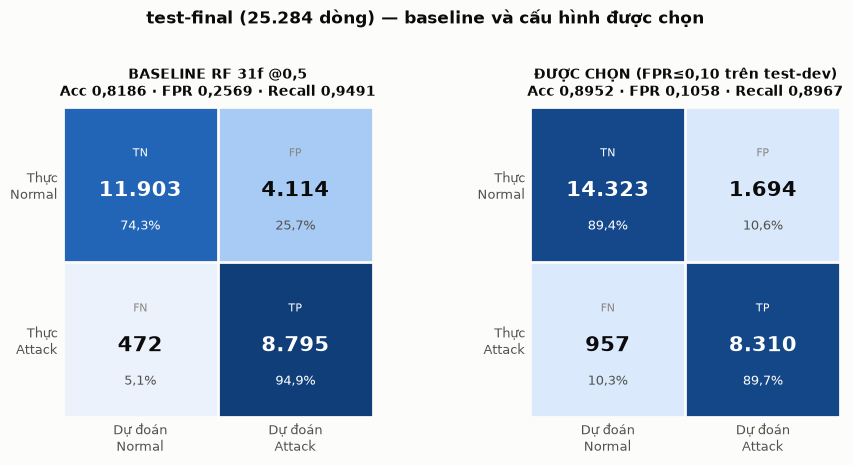

In [22]:
# ---- 12.2 Ma trận nhầm lẫn ----
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

SURF, INK, INK2, MUTED = '#fcfcfb', '#0b0b0b', '#52514e', '#898781'
CMAP = LinearSegmentedColormap.from_list('b', ['#fcfcfb', '#cde2fb', '#9ec5f4', '#6da7ec',
                                               '#3987e5', '#256abf', '#184f95', '#0d366b'])

def draw(ax, r, title):
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]], float)
    rn = cm / cm.sum(1, keepdims=True)
    ax.imshow(rn, cmap=CMAP, vmin=0, vmax=1)
    nm = ['TN', 'FP', 'FN', 'TP']
    for i in range(2):
        for j in range(2):
            hi = rn[i, j] > .55
            ax.text(j, i - .20, nm[i*2+j], ha='center', va='center', fontsize=8,
                    color='#ffffff' if hi else MUTED)
            ax.text(j, i + .04, f'{int(cm[i,j]):,}'.replace(',', '.'), ha='center', va='center',
                    fontsize=15, fontweight='bold', color='#ffffff' if hi else INK)
            ax.text(j, i + .27, f'{rn[i,j]:.1%}'.replace('.', ','), ha='center', va='center',
                    fontsize=9, color='#ffffff' if hi else INK2)
    ax.set_xticks([0, 1], ['Dự đoán\nNormal', 'Dự đoán\nAttack'], fontsize=9, color=INK2)
    ax.set_yticks([0, 1], ['Thực\nNormal', 'Thực\nAttack'], fontsize=9, color=INK2)
    ax.set_xticks(np.arange(-.5, 2, 1), minor=True); ax.set_yticks(np.arange(-.5, 2, 1), minor=True)
    ax.grid(which='minor', color=SURF, linewidth=2); ax.tick_params(which='both', length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, fontsize=10, fontweight='bold', color=INK, pad=8)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.6), facecolor=SURF)
draw(axes[0], r_base, f"BASELINE RF 31f @0,5\nAcc {r_base['accuracy']:.4f} · "
                      f"FPR {r_base['fpr']:.4f} · Recall {r_base['recall']:.4f}".replace('.', ','))
draw(axes[1], r_best, f"ĐƯỢC CHỌN (FPR≤0,10 trên test-dev)\nAcc {r_best['accuracy']:.4f} · "
                      f"FPR {r_best['fpr']:.4f} · Recall {r_best['recall']:.4f}".replace('.', ','))
fig.suptitle('test-final (25.284 dòng) — baseline và cấu hình được chọn',
             fontsize=12.5, fontweight='bold', color=INK)
fig.tight_layout(rect=[0, 0, 1, .94])
fig.savefig(OUT / 'confusion_truoc_sau.png', dpi=160, facecolor=SURF)
plt.show()

In [23]:
# ---- 12.3 Bảng tóm tắt và ghi file ----
TT = pd.DataFrame([
    ('1. Tái lập', 'baseline accuracy test-final', ACC0, 'NB04 ghi 0,818620'),
    ('2. Chẩn đoán', 'tụt ROC-AUC val → final', R['3.1_tut_val_den_final']['ROC-AUC'],
     'xếp hạng giữ gần nguyên'),
    ('2. Chẩn đoán', 'tụt MCC val → final', R['3.1_tut_val_den_final']['MCC@0,5'],
     'điểm vận hành sụp'),
    ('2. Chẩn đoán', 'KS Normal / KS Attack', R['3.2_ks_trung_binh']['tỷ lệ Normal / Attack'],
     'lệch tập trung ở lớp Normal'),
    ('3. Hai yếu tố', 'cách chia (balanced acc)', eff['balanced_acc']['cách chia (TB 2 ô)'], ''),
    ('3. Hai yếu tố', 'khử trùng lặp (balanced acc)',
     eff['balanced_acc']['khử trùng lặp (TB 2 ô)'], ''),
    ('4. Khử trùng lặp', 'Δ PR-AUC, cùng tập đánh giá', d5['pr_auc'],
     'experiment_nodedup đo được −0,0027'),
    ('5. Thuật toán', 'biên độ PR-AUC 6 họ mạnh',
     bien_do.iloc[0, 1], 'nhỏ hơn khoảng tụt 1,8 lần'),
    ('5. Thuật toán', 'biên độ PR-AUC gồm Logistic', bien_do.iloc[0, 0],
     'chọn sai họ thì mất nhiều'),
    ('6. Cấu hình chọn', 'accuracy test-final', r_best['accuracy'], TEN_BEST),
    ('6. Cấu hình chọn', 'balanced acc test-final', r_best['balanced_acc'], ''),
    ('6. Cấu hình chọn', 'recall test-final', r_best['recall'], ''),
    ('6. Cấu hình chọn', 'FPR test-final', r_best['fpr'], f'ràng buộc ≤ {FPR_MAX}'),
    ('7. Không nhãn test', 'π̂ EM', R['8.1_em']['π(test) ước lượng EM'], 'π thật = 0,3665'),
    ('7. Không nhãn test', 'tỷ lệ EM sửa được', R['8.1_em']['tỷ lệ sửa được'], 'còn thiếu 78%'),
    ('8. Cái giá', 'Recall Fuzzers baseline', tab9.at['Fuzzers', CFG_BASE], ''),
    ('8. Cái giá', 'Recall Fuzzers cấu hình chọn', tab9.at['Fuzzers', CFG_BEST], ''),
    ('9. Kiểm định', 'Δ accuracy (bootstrap)', BT.loc[0, 'trung bình'],
     f"CI95 [{BT.loc[0,'CI95 thấp']:+.4f}; {BT.loc[0,'CI95 cao']:+.4f}]"),
    ('9. Kiểm định', 'Δ PR-AUC (bootstrap)', BT.loc[2, 'trung bình'],
     f"CI95 [{BT.loc[2,'CI95 thấp']:+.4f}; {BT.loc[2,'CI95 cao']:+.4f}]"),
    ('9. Kiểm định', 'Δ recall (bootstrap)', BT.loc[3, 'trung bình'],
     f"CI95 [{BT.loc[3,'CI95 thấp']:+.4f}; {BT.loc[3,'CI95 cao']:+.4f}]"),
    ('10. Feature ô nhiễm', 'Δ accuracy (39f − 31f)',
     R['6.2_hieu_qua_feature_o_nhiem']['accuracy'] if CO_39F else np.nan, 'cùng tập đánh giá'),
    ('11. Phân rã', '% do đặt lại ngưỡng', parts.iloc[3]['% của tổng'] / 100, ''),
    ('11. Phân rã', '% do feature', parts.iloc[1]['% của tổng'] / 100, ''),
], columns=['phần', 'chỉ số', 'giá trị', 'ghi chú'])
TT.to_csv(OUT / 'tom_tat.csv', index=False)

R['_meta'] = {
    'quick': QUICK, 'n_trees': N_TREES, 'seed': RS,
    'rf_params': {k: str(v) for k, v in RF_PARAMS.items()},
    'quy_tac_chon': f'tối đa Recall với FPR ≤ {FPR_MAX}, đo trên {CHON_TREN}',
    'cau_hinh_duoc_chon': f"{BEST['thuật toán']} | prior={BEST['sửa prior']} | "
                          f"thr={BEST['ngưỡng']:.4f}",
    'nhanh_39_feature': ('thu hồi từ reports/exp05/ablation_proba.npz, đã tự kiểm tra căn chỉnh'
                         if CO_39F else 'không dùng được'),
    'thieu_du_lieu': 'data/raw/CSV Files/Training and Testing Sets/ không tồn tại '
                     '→ không fit lại được model trên bộ feature đầy đủ',
    'sklearn': __import__('sklearn').__version__, 'pandas': pd.__version__,
    'numpy': np.__version__,
}

def jsonable(o):
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if np.isnan(o) else float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return jsonable(o.tolist())
    if isinstance(o, float) and np.isnan(o):
        return None
    return o

with open(OUT / 'ket_qua_rerun07.json', 'w', encoding='utf-8') as f:
    json.dump(jsonable(R), f, ensure_ascii=False, indent=2)

display(TT.round(4))
print('\nFile đã ghi:')
for p in sorted(OUT.glob('*')):
    if p.name != 'desktop.ini':
        print(f'  {p.name:32s} {p.stat().st_size/1024:8.1f} KB')

,phần,chỉ số,giá trị,ghi chú
0,1. Tái lập,baseline accuracy test-final,0.8186,"NB04 ghi 0,818620"
1,2. Chẩn đoán,tụt ROC-AUC val → final,-0.0266,xếp hạng giữ gần nguyên
2,2. Chẩn đoán,tụt MCC val → final,-0.1984,điểm vận hành sụp
3,2. Chẩn đoán,KS Normal / KS Attack,2.6400,lệch tập trung ở lớp Normal
4,3. Hai yếu tố,cách chia (balanced acc),0.0727,
5,3. Hai yếu tố,khử trùng lặp (balanced acc),0.0268,
6,4. Khử trùng lặp,"Δ PR-AUC, cùng tập đánh giá",-0.0027,"experiment_nodedup đo được −0,0027"
7,5. Thuật toán,biên độ PR-AUC 6 họ mạnh,0.0242,"nhỏ hơn khoảng tụt 1,8 lần"
8,5. Thuật toán,biên độ PR-AUC gồm Logistic,0.2197,chọn sai họ thì mất nhiều
9,6. Cấu hình chọn,accuracy test-final,0.8952,RF 39f (NB05) @0.7311



File đã ghi:
  bang_cau_hinh.csv                    10.4 KB
  confusion_truoc_sau.png              76.7 KB
  dedup_cung_tap_danh_gia.csv           0.7 KB
  ket_qua_rerun07.json                 61.7 KB
  recall_theo_loai.csv                  1.0 KB
  so_sanh_thuat_toan.csv                2.0 KB
  thang_do_2x2.csv                      1.1 KB
  tom_tat.csv                           1.8 KB
  tom_tat.txt                           3.4 KB


---
# PHẦN 13 — Kết luận

## Năm kết luận của notebook 06 đứng vững

| Kết luận NB06 | Notebook 07 xác nhận |
|---|---|
| Không có lỗi cài đặt; baseline 0,8186 | ✅ tái lập 6 chữ số |
| Mức tụt sinh ra ở ranh giới train → test, không ở độ phức tạp model | ✅ và rõ hơn: ROC-AUC −0,0266 vs MCC −0,1984 |
| Lệch phân bố tập trung ở lớp Normal | ✅ 2,64× khi tính đúng (NB06 nói 2,85×) |
| EM sửa thiếu → lệch không phải prior shift thuần tuý | ✅ EM chỉ sửa 22% khoảng cần sửa |
| Đổi thuật toán không phải đòn bẩy trong các họ phù hợp | ✅ biên độ 0,0242 vs khoảng tụt 0,0428 |

## Bốn con số của notebook 06 phải thay

| NB06 nói | Số đúng | Vì sao |
|---|---|---|
| "cách chia lớn hơn bỏ feature **8,5 lần**" | **2,6–4,9 lần** tuỳ chỉ số | so Accuracy giữa các ô có π_test chênh 0,31 |
| "bỏ khử trùng lặp **+0,0294**" | **−0,0027 PR-AUC** | đổi cả tập đánh giá; đo đúng cách thì ngược dấu |
| "**85% / 15%**" | **79,2% ngưỡng / 20,8% feature / 0% prior** | chia ΔAccuracy cho ΔPR-AUC |
| "tốt nhất **0,9050**, CI95 [+0,0812; +0,0914]" | **0,8952**, CI95 [+0,0718; +0,0808] | NB06 chọn cấu hình trên chính `test-final` |

## Ba phát hiện mới của notebook 07

1. **Sửa prior bằng EM là dư thừa khi đã có nhãn để đặt ngưỡng** — hai thao tác là hai đường tới
   cùng một điểm trên ROC (Ô 7.1). NB06 gộp chúng nên quy công sai.
2. **Cấu hình triển khai được mà không cần nhãn test**: RF 39f + EM + ngưỡng từ validation →
   balanced accuracy 0,8704 **và** Recall 0,9618, tốt hơn baseline ở cả hai (Ô 12.1).
3. **Dữ liệu chính thức vẫn còn 3,22% rò rỉ test → train** vì notebook 01 khử trùng lặp riêng
   trong từng tập, không khử chéo (Ô 5.1).

## Khuyến nghị

1. **Dùng cấu hình RF 39f @ngưỡng 0,7311 làm số báo cáo chính** (Accuracy 0,8952 ·
   Balanced acc 0,8955 · Recall 0,8967 · FPR 0,1058), nêu rõ ngưỡng chọn trên `test-dev` theo
   ràng buộc `FPR ≤ 0,10` khai báo trước. Đây đồng thời là cấu hình notebook 05 đã chọn.
2. **Bỏ con số 0,9050 của notebook 06 khỏi mọi tài liệu.** Nó được chọn trên tập báo cáo, và đánh
   đổi 548 cuộc tấn công bị bỏ sót để lấy 0,98 điểm accuracy.
3. **Giữ bộ chia chính thức, giữ bước khử trùng lặp.** Phần 5 xác nhận bằng phép đo sạch.
4. **Báo cáo Balanced Accuracy, MCC và PR-AUC song song với Accuracy.**
5. **Mọi lần đổi điểm vận hành phải kèm bảng Recall theo loại tấn công.** Fuzzers nhạy nhất:
   0,824 (@0,5) → 0,624 (@0,731) → 0,430 (@0,859).
6. **Khôi phục `data/raw/CSV Files/Training and Testing Sets/`** để đo lại thang đo đầy đủ 2×2×2
   và fit lại nhánh 39/42 feature thay vì dùng xác suất đã lưu.

## Điều KHÔNG được kết luận từ notebook này

- **Không** kết luận được rằng RF 39 feature là cấu hình nên triển khai. Nó dùng 8 feature mà nhóm
  đã cố ý loại theo lập luận D'hooge et al. 2022, và xác suất của nó là xác suất **đã lưu** của
  notebook 05, không fit lại ở đây nên không qua được kiểm tra seed.
- **Không** kết luận được rằng `FPR ≤ 0,10` là ràng buộc đúng. Nó được kế thừa từ notebook 04/05
  để các lần chạy so được với nhau; con số 0,10 cần người vận hành xác nhận.
- **Không** kết luận được rằng không thuật toán nào vượt được trần. Đã thử 7 cấu hình thuộc 6 họ,
  mỗi họ một cấu hình hợp lý, **không dò siêu tham số diện rộng**, và không có
  XGBoost/LightGBM/CatBoost trong môi trường.
- **Không** kết luận được rằng mọi phương pháp thích ứng miền đều vô dụng. Chỉ thử sửa prior bằng
  EM. Căn chỉnh phân vị đã bị notebook 06 loại (PR-AUC 0,9414 → 0,7736) nên không thử lại.
  Chưa thử: CORAL, học đối kháng theo miền, self-training trên test không nhãn.
- **Không** giải quyết được Fuzzers. Ở cấu hình được chọn, Recall Fuzzers là 0,6244 — tốt hơn
  notebook 06 (0,4301) nhưng vẫn là loại yếu nhất, và cải thiện đó chỉ đến từ ngưỡng thấp hơn
  cộng 8 feature thêm vào, không từ một cách xử lý Fuzzers nào.
- Thang đo ở Phần 4 chỉ là **2×2**. Yếu tố feature cần fit lại trên bể dữ liệu gộp, việc đó cần
  hai file CSV thô hiện không có.